In [1]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import zipfile
import os

zip_path = '/content/drive/MyDrive/HUPA-UCM Diabetes Dataset.zip'
extract_path = '/content/HUPA-UCM_Diabetes_Dataset_extracted'

# Create the extraction directory if it doesn't exist
os.makedirs(extract_path, exist_ok=True)

# Unzip the file
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print(f"ZIP file extracted to: {extract_path}")
print("Contents of the extracted directory:")
for root, dirs, files in os.walk(extract_path):
    for name in files:
        print(os.path.join(root, name))
    for name in dirs:
        print(os.path.join(root, name))

Streaming output truncated to the last 5000 lines.
/content/HUPA-UCM_Diabetes_Dataset_extracted/HUPA-UCM Diabetes Dataset/Raw_Data/HUPA0026P/fitbit/HUPA0026P_sleep_2020-06-24_night_summary.csv
/content/HUPA-UCM_Diabetes_Dataset_extracted/HUPA-UCM Diabetes Dataset/Raw_Data/HUPA0026P/fitbit/HUPA0026P_sleep_2020-07-26_night.csv
/content/HUPA-UCM_Diabetes_Dataset_extracted/HUPA-UCM Diabetes Dataset/Raw_Data/HUPA0026P/fitbit/HUPA0026P_sleep_2020-07-18_night_summary.csv
/content/HUPA-UCM_Diabetes_Dataset_extracted/HUPA-UCM Diabetes Dataset/Raw_Data/HUPA0026P/fitbit/HUPA0026P_cals_2020-07-30.csv
/content/HUPA-UCM_Diabetes_Dataset_extracted/HUPA-UCM Diabetes Dataset/Raw_Data/HUPA0026P/fitbit/HUPA0026P_sleep_2020-05-29_night.csv
/content/HUPA-UCM_Diabetes_Dataset_extracted/HUPA-UCM Diabetes Dataset/Raw_Data/HUPA0026P/fitbit/HUPA0026P_steps_2020-05-20.csv
/content/HUPA-UCM_Diabetes_Dataset_extracted/HUPA-UCM Diabetes Dataset/Raw_Data/HUPA0026P/fitbit/HUPA0026P_heart_2020-08-16.csv
/content/HUPA-

In [3]:
csv_path = '/content/HUPA-UCM_Diabetes_Dataset_extracted/HUPA-UCM Diabetes Dataset/Raw_Data/HUPA0028P/fitbit/HUPA0028P_steps_2022-03-20.csv'
df = pd.read_csv(csv_path)
display(df.head())

,dateTime,value
0,00:00:00,50
1,00:01:00,0
2,00:02:00,0
3,00:03:00,0
4,00:04:00,12


In [4]:
import os
import pandas as pd

# Define extract_path explicitly in this cell to ensure it's always available
extract_path = '/content/HUPA-UCM_Diabetes_Dataset_extracted'

# Re-initialize the dictionary to store correctly loaded dataframes
preprocessed_dataframes = {}
preprocessed_path = os.path.join(extract_path, 'HUPA-UCM Diabetes Dataset', 'Preprocessed')

for root, dirs, files in os.walk(preprocessed_path):
    for file in files:
        if file.endswith('.csv'):
            file_path = os.path.join(root, file)
            try:
                df_name = file.replace('.csv', '')
                # Load with semicolon separator
                df_temp = pd.read_csv(file_path, sep=';')
                # Extract patient_id from filename and add as a new column
                df_temp['patient_id'] = df_name
                preprocessed_dataframes[df_name] = df_temp
                print(f"Reloaded {file} into DataFrame '{df_name}' with semicolon separator and added patient_id.")
            except Exception as e:
                print(f"Error reloading {file}: {e}")

print(f"\nSuccessfully reloaded {len(preprocessed_dataframes)} preprocessed CSV files.")

# Combine all DataFrames into a single one
combined_df = pd.concat(preprocessed_dataframes.values(), ignore_index=True)

print("\nCombined DataFrame created successfully.")
display(combined_df.head())
print(f"Shape of the combined DataFrame: {combined_df.shape}")

Reloaded HUPA0015P.csv into DataFrame 'HUPA0015P' with semicolon separator and added patient_id.
Reloaded HUPA0017P.csv into DataFrame 'HUPA0017P' with semicolon separator and added patient_id.
Reloaded HUPA0002P.csv into DataFrame 'HUPA0002P' with semicolon separator and added patient_id.
Reloaded HUPA0011P.csv into DataFrame 'HUPA0011P' with semicolon separator and added patient_id.
Reloaded HUPA0022P.csv into DataFrame 'HUPA0022P' with semicolon separator and added patient_id.
Reloaded HUPA0009P.csv into DataFrame 'HUPA0009P' with semicolon separator and added patient_id.
Reloaded HUPA0005P.csv into DataFrame 'HUPA0005P' with semicolon separator and added patient_id.
Reloaded HUPA0027P.csv into DataFrame 'HUPA0027P' with semicolon separator and added patient_id.
Reloaded HUPA0020P.csv into DataFrame 'HUPA0020P' with semicolon separator and added patient_id.
Reloaded HUPA0007P.csv into DataFrame 'HUPA0007P' with semicolon separator and added patient_id.
Reloaded HUPA0021P.csv into Da

,time,glucose,calories,heart_rate,steps,basal_rate,bolus_volume_delivered,carb_input,patient_id
0,2019-03-27T16:15:00,60.000000,17.69812,109.162602,15.0,0.0,0.0,0.0,HUPA0015P
1,2019-03-27T16:20:00,58.666667,6.77440,89.536585,0.0,0.0,0.0,0.0,HUPA0015P
2,2019-03-27T16:25:00,57.333333,6.01228,56.885965,32.0,0.0,0.0,0.0,HUPA0015P
3,2019-03-27T16:30:00,56.000000,5.50420,58.721311,0.0,0.0,0.0,0.0,HUPA0015P
4,2019-03-27T16:35:00,54.000000,4.65740,58.177966,0.0,0.0,0.0,0.0,HUPA0015P


Shape of the combined DataFrame: (309392, 9)


Ensemble Tube Loss Method

TCN + Tube

In [ ]:
import pandas as pd
import numpy as np
import datetime
import tensorflow as tf
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
!pip install keras-tcn # Corrected installation to keras-tcn
from tcn import TCN
import time

In [ ]:
# ------------------- DATA PREP (GLUCOSE) -------------------

# Sort properly (VERY IMPORTANT for time series)
combined_df = combined_df.sort_values(['patient_id', 'time'])

# Keep only required columns
df = combined_df[['patient_id', 'time', 'glucose']].copy()

# Handle missing values
df['glucose'] = pd.to_numeric(df['glucose'], errors='coerce')
df['glucose'] = df['glucose'].ffill()

# -------------------
# OPTIONAL BUT IMPORTANT (for better MPIW)
# -------------------

# 1. Smoothing (reduces noise)
df['glucose'] = df['glucose'].rolling(window=3, min_periods=1).mean()

# 2. Clipping (removes extreme outliers)
df['glucose'] = df['glucose'].clip(70, 250)

In [ ]:
# ------------------- NORMALIZATION (COMBINED_DF) -------------------

# Ensure sorted (VERY IMPORTANT)
combined_df = combined_df.sort_values(['patient_id', 'time'])

# Clean glucose
combined_df['glucose'] = pd.to_numeric(combined_df['glucose'], errors='coerce')
combined_df['glucose'] = combined_df['glucose'].ffill()

# Optional (recommended)
combined_df['glucose'] = combined_df['glucose'].rolling(window=3, min_periods=1).mean()
combined_df['glucose'] = combined_df['glucose'].clip(70, 250)

# -------------------
# GLOBAL NORMALIZATION
# NOTE: despite earlier naming, this computes ONE mean/std across ALL
# patients combined, not per-patient stats. Patients can have very
# different baseline glucose levels, so this is a known simplification -
# a true per-patient z-score would likely improve model quality, but
# would require refactoring every downstream denormalization step too.
# -------------------

data = combined_df['glucose'].values.reshape(-1,1)

mean_data = np.mean(data)
std_data = np.std(data)

data_normalized = (data - mean_data) / std_data

# Add the normalized data back to combined_df as 'glucose_norm'
combined_df['glucose_norm'] = data_normalized

print("Normalization done!")

Normalization done!


In [ ]:
# ------------------- PATIENT-WISE SEQUENCE CREATION -------------------

def truncate_patientwise(df, window=24):

    X_all, y_all = [], []

    for pid in df['patient_id'].unique():

        patient = df[df['patient_id'] == pid].sort_values('time')

        x = patient['glucose_norm'].values.reshape(-1,1)

        if len(x) < window + 1:
            continue

        for i in range(len(x) - window):

            X_all.append(x[i:i+window])
            y_all.append(x[i+window])

    return np.array(X_all), np.array(y_all)


# Create sequences
X_in, X_out = truncate_patientwise(combined_df, window=24)

print("X shape:", X_in.shape)
print("y shape:", X_out.shape)

X shape: (308792, 24, 1)
y shape: (308792, 1)


In [ ]:
# ------------------- TRAIN / VAL / TEST SPLIT -------------------

n = X_in.shape[0]

train_end = int(n * 0.8)
val_end = int(n * 0.9)

train_x = X_in[:train_end]
val_x   = X_in[train_end:val_end]
test_x  = X_in[val_end:]

train_y = X_out[:train_end]
val_y   = X_out[train_end:val_end]
test_y  = X_out[val_end:]


# -------------------


print("Train:", train_x.shape)
print("Val:", val_x.shape)
print("Test:", test_x.shape)

Train: (247033, 24, 1)
Val: (30879, 24, 1)
Test: (30880, 24, 1)


In [ ]:
# ------------------- FINAL FIXED TUBE LOSS -------------------

q = 0.95        # target coverage
r = 0.5         # midpoint control (0.5 = center)
delta = 0.01    # width penalty (tune this)

def confidence_loss(y_true, y_pred):

    # flatten true values
    y_true = y_true[:, 0]

    # predicted bounds
    f1 = y_pred[:, 0]
    f2 = y_pred[:, 1]

    # ensure correct ordering
    lower = tf.minimum(f1, f2)
    upper = tf.maximum(f1, f2)

    # -------------------
    # CORRECT MIDPOINT
    # -------------------
    mid = lower + r * (upper - lower)

    # -------------------
    # OUTSIDE LOSS (coverage)
    # -------------------
    loss_outside = tf.where(
        y_true > upper,
        q * (y_true - upper),
        tf.where(
            y_true < lower,
            q * (lower - y_true),
            0.0
        )
    )

    # -------------------
    # INSIDE LOSS (tightness)
    # -------------------
    loss_inside = tf.where(
        y_true > mid,
        (1 - q) * (upper - y_true),
        (1 - q) * (y_true - lower)
    )

    # -------------------
    # WIDTH PENALTY
    # -------------------
    width_penalty = delta * (upper - lower)

    # -------------------
    # FINAL LOSS
    # -------------------
    total_loss = loss_outside + loss_inside + width_penalty

    return tf.reduce_mean(total_loss)

In [ ]:
# ------------------- TCN MODEL (FIXED) -------------------

from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model
from tcn import TCN

def build_tcn_model(input_shape, num_outputs=2):

    inputs = Input(shape=input_shape)

    x = TCN(
        nb_filters=32,              # 🔽 reduced → avoids overfitting
        kernel_size=3,
        nb_stacks=1,
        dilations=(1, 2, 4, 8),
        dropout_rate=0.1,           # 🔥 lower → better learning
        return_sequences=False
    )(inputs)

    x = Dense(32, activation='relu')(x)   # 🔥 extra layer improves stability

    outputs = Dense(num_outputs)(x)       # (f1, f2)

    model = Model(inputs, outputs)

    return model

In [ ]:
# =========================
# ENSEMBLE TRAINING (TCN VERSION) - LEAK-FREE CALIBRATION
# =========================

global_glucose_data = combined_df['glucose'].values
mean_data = np.mean(global_glucose_data)
std_data = np.std(global_glucose_data)

print("\n--- Input Data Diagnostics ---")
for _name, _arr in [('train_x', train_x), ('train_y', train_y), ('val_x', val_x), ('val_y', val_y)]:
    if np.isnan(_arr).any():
        print(f"Warning: NaN values found in {_name}!")
    if np.isinf(_arr).any():
        print(f"Warning: Inf values found in {_name}!")
print("------------------------------")

results = []
batch_size = 64
all_test_preds = []
all_val_preds = []   # FIX: keep every run's val predictions so we can calibrate without touching test data

for run in range(1, 6):

    print(f"\n===== RUN {run} ====")
    tf.keras.utils.set_random_seed(run)

    
    model = build_tcn_model(input_shape=(train_x.shape[1], train_x.shape[2]))

    model.compile(
        loss=confidence_loss,
        optimizer=Adam(learning_rate=0.001, clipnorm=1.0)
    )

    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=5, restore_best_weights=True
    )

    model.fit(
        train_x, train_y,
        validation_data=(val_x, val_y),
        epochs=100,
        batch_size=batch_size,
        verbose=1,
        callbacks=[early_stopping]
    )

    val_pred = model.predict(val_x, verbose=0)
    all_val_preds.append(val_pred)

    val_lower = np.minimum(val_pred[:, 0], val_pred[:, 1])
    val_upper = np.maximum(val_pred[:, 0], val_pred[:, 1])

    val_lower = val_lower * std_data + mean_data
    val_upper = val_upper * std_data + mean_data
    val_true  = val_y.squeeze() * std_data + mean_data

    val_picp = np.mean((val_lower <= val_true) & (val_true <= val_upper))
    val_mpiw = np.mean(val_upper - val_lower)

    print("Val PICP:", round(val_picp, 4), " Val MPIW:", round(val_mpiw, 2))

    results.append({'run': run, 'val_picp': val_picp, 'val_mpiw': val_mpiw})

    test_pred = model.predict(test_x, verbose=0)
    all_test_preds.append(test_pred)
    np.save(f"test_pred_run{run}.npy", test_pred)


all_test_preds = np.array(all_test_preds)
all_val_preds  = np.array(all_val_preds)

lower_preds = np.minimum(all_test_preds[:, :, 0], all_test_preds[:, :, 1])
upper_preds = np.maximum(all_test_preds[:, :, 0], all_test_preds[:, :, 1])

val_lower_preds = np.minimum(all_val_preds[:, :, 0], all_val_preds[:, :, 1])
val_upper_preds = np.maximum(all_val_preds[:, :, 0], all_val_preds[:, :, 1])

final_lower = np.percentile(lower_preds, 30, axis=0)
final_upper = np.percentile(upper_preds, 70, axis=0)

final_val_lower = np.percentile(val_lower_preds, 30, axis=0)
final_val_upper = np.percentile(val_upper_preds, 70, axis=0)

final_lower = final_lower * std_data + mean_data
final_upper = final_upper * std_data + mean_data
test_true   = test_y.squeeze() * std_data + mean_data

final_val_lower = final_val_lower * std_data + mean_data
final_val_upper = final_val_upper * std_data + mean_data
val_true_full   = val_y.squeeze() * std_data + mean_data

picp = np.mean((final_lower <= test_true) & (test_true <= final_upper))
mpiw = np.mean(final_upper - final_lower)

print("\n===== FINAL ENSEMBLE RESULTS (test, uncalibrated) ====")
print("PICP:", round(picp, 4))
print("MPIW:", round(mpiw, 2))

# CALIBRATION - FIXED: scale learned on VALIDATION, applied to TEST (no leakage)
target_picp = 0.95

val_picp_ens = np.mean((final_val_lower <= val_true_full) & (val_true_full <= final_val_upper))

if val_picp_ens > 0:
    scale = target_picp / val_picp_ens

    mid_test = (final_upper + final_lower) / 2
    final_lower_cal = mid_test - scale * (mid_test - final_lower)
    final_upper_cal = mid_test + scale * (final_upper - mid_test)

    picp_cal = np.mean((final_lower_cal <= test_true) & (test_true <= final_upper_cal))
    mpiw_cal = np.mean(final_upper_cal - final_lower_cal)

    print("\n===== CALIBRATED RESULTS (scale fit on val, evaluated on test) ====")
    print("Validation ensemble PICP (pre-scale):", round(val_picp_ens, 4))
    print("Scale factor applied:", round(scale, 4))
    print("Test PICP (calibrated):", round(picp_cal, 4))
    print("Test MPIW (calibrated):", round(mpiw_cal, 2))



--- Input Data Diagnostics ---
------------------------------

===== RUN 1 ====
Epoch 1/100
3860/3860 ━━━━━━━━━━━━━━━━━━━━ 41s 7ms/step - loss: 0.0140 - val_loss: 0.0039
Epoch 2/100
3860/3860 ━━━━━━━━━━━━━━━━━━━━ 18s 5ms/step - loss: 0.0059 - val_loss: 0.0036
Epoch 3/100
3860/3860 ━━━━━━━━━━━━━━━━━━━━ 18s 5ms/step - loss: 0.0050 - val_loss: 0.0037
Epoch 4/100
3860/3860 ━━━━━━━━━━━━━━━━━━━━ 18s 5ms/step - loss: 0.0046 - val_loss: 0.0024
Epoch 5/100
3860/3860 ━━━━━━━━━━━━━━━━━━━━ 17s 4ms/step - loss: 0.0044 - val_loss: 0.0031
Epoch 6/100
3860/3860 ━━━━━━━━━━━━━━━━━━━━ 17s 4ms/step - loss: 0.0042 - val_loss: 0.0028
Epoch 7/100
3860/3860 ━━━━━━━━━━━━━━━━━━━━ 19s 5ms/step - loss: 0.0041 - val_loss: 0.0023
Epoch 8/100
3860/3860 ━━━━━━━━━━━━━━━━━━━━ 18s 5ms/step - loss: 0.0040 - val_loss: 0.0024
Epoch 9/100
3860/3860 ━━━━━━━━━━━━━━━━━━━━ 17s 4ms/step - loss: 0.0039 - val_loss: 0.0024
Epoch 10/100
3860/3860 ━━━━━━━━━━━━━━━━━━━━ 18s 5ms/step - loss: 0.0038 - val_loss: 0.0024
Epoch 11/100
3860/

In [ ]:
# ================== Save results ==================

# Convert results list to DataFrame
results_df = pd.DataFrame(results)

# Initialize summary_df as empty DataFrame
summary_df = pd.DataFrame()

# 🔥 Add summary stats (useful for glucose analysis)
# Only call describe if the DataFrame is not empty
if not results_df.empty:
    summary_df = results_df.describe()
else:
    print("Warning: results_df is empty, cannot generate meaningful summary statistics.")

# Save both detailed + summary in ONE Excel file
with pd.ExcelWriter("ensemble_results_glucose.xlsx") as writer:
    results_df.to_excel(writer, sheet_name="Run_Wise_Results", index=False)
    # Only write summary_df to Excel if it's not empty
    if not summary_df.empty:
        summary_df.to_excel(writer, sheet_name="Summary_Stats")
    else:
        print("Skipping writing 'Summary_Stats' sheet as summary_df is empty.")

print("\nResults saved to Excel (ensemble_results_glucose.xlsx).")


Results saved to Excel (ensemble_results_glucose.xlsx).


In [ ]:
# ================== Save test data ==================

# Save normalized test data (as used in model)
np.save("test_X_glucose.npy", test_x)
np.save("test_y_glucose.npy", test_y)

# 🔥 ALSO save denormalization parameters (VERY IMPORTANT)
np.save("glucose_mean.npy", mean_data)
np.save("glucose_std.npy", std_data)

print("Test data and normalization parameters saved successfully.")

Test data and normalization parameters saved successfully.


In [ ]:
import numpy as np
import os

# ================== CONFIG ==================
base_path = "./"
runs = 5

# ================== LOAD DATA ==================

# Corrected filename for test_y
test_y = np.load(os.path.join(base_path, "test_y_glucose.npy"))

mean_data = np.load(os.path.join(base_path, "glucose_mean.npy"))
std_data  = np.load(os.path.join(base_path, "glucose_std.npy"))

# Denormalize true values
test_true = test_y.squeeze() * std_data + mean_data

# ================== LOAD BOUNDS ==================

all_preds = []

for run in range(1, runs + 1):
    # Load the combined prediction file
    preds = np.load(os.path.join(base_path, f"test_pred_run{run}.npy"))
    all_preds.append(preds)

all_preds = np.array(all_preds) # Shape (runs, samples, 2)

# Separate lower and upper bounds from the loaded predictions
all_lower = np.minimum(all_preds[:, :, 0], all_preds[:, :, 1])
all_upper = np.maximum(all_preds[:, :, 0], all_preds[:, :, 1])

# ================== METHOD 1: PERCENTILE ENSEMBLE ==================

final_lower = np.percentile(all_lower, 30, axis=0)
final_upper = np.percentile(all_upper, 70, axis=0)

final_lower = final_lower * std_data + mean_data
final_upper = final_upper * std_data + mean_data

picp = np.mean((final_lower <= test_true) & (test_true <= final_upper))
mpiw = np.mean(final_upper - final_lower)

print("\n===== PERCENTILE ENSEMBLE RESULTS ====")
print("PICP:", round(picp, 4))
print("MPIW:", round(mpiw, 2))

# ================== METHOD 2: GAUSSIAN (YOUR ADDITION) ==================

# Mean across runs
mean_lower = np.mean(all_lower, axis=0)
mean_upper = np.mean(all_upper, axis=0)

# Std deviation across runs
sigma_lower = np.std(all_lower, axis=0, ddof=1)
sigma_upper = np.std(all_upper, axis=0, ddof=1)

print("\n===== UNCERTAINTY (RUN VARIATION) ====")
print("Avg Sigma Lower:", np.mean(sigma_lower))
print("Avg Sigma Upper:", np.mean(sigma_upper))

#   YOUR FORMULA
factor = 1.96 * (1 / np.sqrt(runs))

new_upper = mean_upper + factor * sigma_upper
new_lower = mean_lower - factor * sigma_lower

# Denormalize
new_upper = new_upper * std_data + mean_data
new_lower = new_lower * std_data + mean_data

# True values (your format)
test_y_true = np.squeeze(test_y) * std_data + mean_data # Use test_y directly as it's already 1D

# Metrics
PICP_gauss = np.mean((new_upper >= test_y_true) & (new_lower <= test_y_true))
MPIW_gauss = np.mean(new_upper - new_lower)

print("\n===== GAUSSIAN BOUNDS RESULTS ====")
print("PICP:", round(PICP_gauss, 4))
print("MPIW:", round(MPIW_gauss, 2))

# ================== OPTIONAL: CALIBRATION ==================

target_picp = 0.95

if picp > 0:
    scale = target_picp / picp

    mid = (final_upper + final_lower) / 2

    final_lower_cal = mid - scale * (mid - final_lower)
    final_upper_cal = mid + scale * (final_upper - mid)

    picp_cal = np.mean((final_lower_cal <= test_true) & (test_true <= final_upper_cal))
    mpiw_cal = np.mean(final_upper_cal - final_lower_cal)

    print("\n===== CALIBRATED RESULTS ====")
    print("PICP:", round(picp_cal, 4))
    print("MPIW:", round(mpiw_cal, 2))


===== PERCENTILE ENSEMBLE RESULTS ====
PICP: 0.9822
MPIW: 4.03

===== UNCERTAINTY (RUN VARIATION) ====
Avg Sigma Lower: 0.010359682
Avg Sigma Upper: 0.013290565

===== GAUSSIAN BOUNDS RESULTS ====
PICP: 0.9887
MPIW: 4.81

===== CALIBRATED RESULTS ====
PICP: 0.9795
MPIW: 3.9


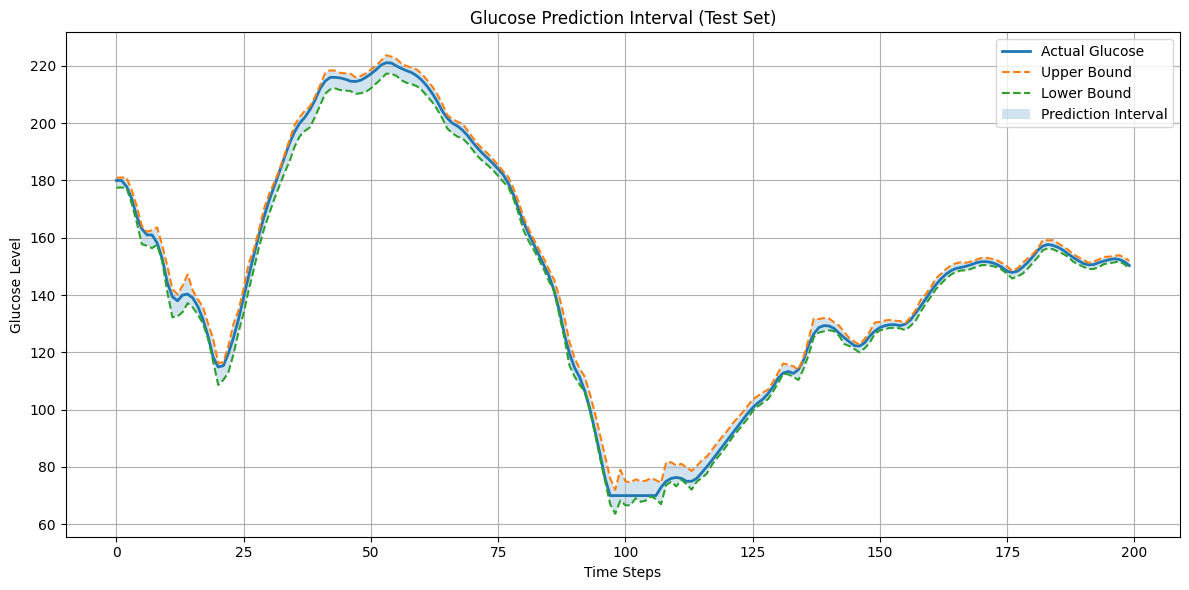

In [ ]:
import matplotlib.pyplot as plt

# ================== SELECT WINDOW ==================
start = 0
end = 200   # change as needed

subset_range = range(start, end)

# ================== PLOT ==================

plt.figure(figsize=(12, 6))

# Actual glucose values
plt.plot(subset_range, test_y_true[start:end],
         label='Actual Glucose', linewidth=2)

# Prediction bounds (Gaussian or percentile — whichever you're analyzing)
plt.plot(subset_range, new_upper[start:end],
         label='Upper Bound', linestyle='--')

plt.plot(subset_range, new_lower[start:end],
         label='Lower Bound', linestyle='--')

# Interval shading
plt.fill_between(subset_range,
                 new_lower[start:end],
                 new_upper[start:end],
                 alpha=0.2,
                 label='Prediction Interval')

# ================== LABELS ==================

plt.xlabel('Time Steps')
plt.ylabel('Glucose Level')
plt.title('Glucose Prediction Interval (Test Set)')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Implementing LSTM+TUBE


In [ ]:
# ------------------- LSTM MODEL (FIXED) -------------------

from tensorflow.keras.layers import Input, Dense, LSTM, Dropout
from tensorflow.keras.models import Model

def build_lstm_model(input_shape, num_outputs=2):

    inputs = Input(shape=input_shape)

    # 🔥 LSTM layers
    x = LSTM(
        32,
        return_sequences=True
    )(inputs)

    x = Dropout(0.1)(x)     # same idea as TCN dropout

    x = LSTM(
        16,
        return_sequences=False
    )(x)

    # 🔥 Dense layer
    x = Dense(32, activation='relu')(x)

    # 🔥 Output layer (unchanged: lower & upper bounds)
    outputs = Dense(num_outputs)(x)

    model = Model(inputs, outputs)

    return model

In [ ]:
# =========================
# ENSEMBLE TRAINING (LSTM VERSION) - LEAK-FREE CALIBRATION
# =========================

global_glucose_data = combined_df['glucose'].values
mean_data = np.mean(global_glucose_data)
std_data = np.std(global_glucose_data)

print("\n--- Input Data Diagnostics ---")
for _name, _arr in [('train_x', train_x), ('train_y', train_y), ('val_x', val_x), ('val_y', val_y)]:
    if np.isnan(_arr).any():
        print(f"Warning: NaN values found in {_name}!")
    if np.isinf(_arr).any():
        print(f"Warning: Inf values found in {_name}!")
print("------------------------------")

results = []
batch_size = 64
all_test_preds = []
all_val_preds = []   # FIX: keep every run's val predictions so we can calibrate without touching test data

for run in range(1, 6):

    print(f"\n===== RUN {run} ====")
    tf.keras.utils.set_random_seed(run)

    # CHANGED: TCN -> LSTM
    model = build_lstm_model(input_shape=(train_x.shape[1], train_x.shape[2]))

    model.compile(
        loss=confidence_loss,
        optimizer=Adam(learning_rate=0.001, clipnorm=1.0)
    )

    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=5, restore_best_weights=True
    )

    model.fit(
        train_x, train_y,
        validation_data=(val_x, val_y),
        epochs=100,
        batch_size=batch_size,
        verbose=1,
        callbacks=[early_stopping]
    )

    val_pred = model.predict(val_x, verbose=0)
    all_val_preds.append(val_pred)

    val_lower = np.minimum(val_pred[:, 0], val_pred[:, 1])
    val_upper = np.maximum(val_pred[:, 0], val_pred[:, 1])

    val_lower = val_lower * std_data + mean_data
    val_upper = val_upper * std_data + mean_data
    val_true  = val_y.squeeze() * std_data + mean_data

    val_picp = np.mean((val_lower <= val_true) & (val_true <= val_upper))
    val_mpiw = np.mean(val_upper - val_lower)

    print("Val PICP:", round(val_picp, 4), " Val MPIW:", round(val_mpiw, 2))

    results.append({'run': run, 'val_picp': val_picp, 'val_mpiw': val_mpiw})

    test_pred = model.predict(test_x, verbose=0)
    all_test_preds.append(test_pred)
    np.save(f"test_pred_run{run}.npy", test_pred)


all_test_preds = np.array(all_test_preds)
all_val_preds  = np.array(all_val_preds)

lower_preds = np.minimum(all_test_preds[:, :, 0], all_test_preds[:, :, 1])
upper_preds = np.maximum(all_test_preds[:, :, 0], all_test_preds[:, :, 1])

val_lower_preds = np.minimum(all_val_preds[:, :, 0], all_val_preds[:, :, 1])
val_upper_preds = np.maximum(all_val_preds[:, :, 0], all_val_preds[:, :, 1])

final_lower = np.percentile(lower_preds, 30, axis=0)
final_upper = np.percentile(upper_preds, 70, axis=0)

final_val_lower = np.percentile(val_lower_preds, 30, axis=0)
final_val_upper = np.percentile(val_upper_preds, 70, axis=0)

final_lower = final_lower * std_data + mean_data
final_upper = final_upper * std_data + mean_data
test_true   = test_y.squeeze() * std_data + mean_data

final_val_lower = final_val_lower * std_data + mean_data
final_val_upper = final_val_upper * std_data + mean_data
val_true_full   = val_y.squeeze() * std_data + mean_data

picp = np.mean((final_lower <= test_true) & (test_true <= final_upper))
mpiw = np.mean(final_upper - final_lower)

print("\n===== FINAL ENSEMBLE RESULTS (test, uncalibrated) ====")
print("PICP:", round(picp, 4))
print("MPIW:", round(mpiw, 2))

# CALIBRATION - FIXED: scale learned on VALIDATION, applied to TEST (no leakage)
target_picp = 0.95

val_picp_ens = np.mean((final_val_lower <= val_true_full) & (val_true_full <= final_val_upper))

if val_picp_ens > 0:
    scale = target_picp / val_picp_ens

    mid_test = (final_upper + final_lower) / 2
    final_lower_cal = mid_test - scale * (mid_test - final_lower)
    final_upper_cal = mid_test + scale * (final_upper - mid_test)

    picp_cal = np.mean((final_lower_cal <= test_true) & (test_true <= final_upper_cal))
    mpiw_cal = np.mean(final_upper_cal - final_lower_cal)

    print("\n===== CALIBRATED RESULTS (scale fit on val, evaluated on test) ====")
    print("Validation ensemble PICP (pre-scale):", round(val_picp_ens, 4))
    print("Scale factor applied:", round(scale, 4))
    print("Test PICP (calibrated):", round(picp_cal, 4))
    print("Test MPIW (calibrated):", round(mpiw_cal, 2))



--- Input Data Diagnostics ---
------------------------------

===== RUN 1 ====
Epoch 1/100
3860/3860 ━━━━━━━━━━━━━━━━━━━━ 38s 9ms/step - loss: 0.0152 - val_loss: 0.0039
Epoch 2/100
3860/3860 ━━━━━━━━━━━━━━━━━━━━ 35s 9ms/step - loss: 0.0055 - val_loss: 0.0036
Epoch 3/100
3860/3860 ━━━━━━━━━━━━━━━━━━━━ 36s 9ms/step - loss: 0.0049 - val_loss: 0.0035
Epoch 4/100
3860/3860 ━━━━━━━━━━━━━━━━━━━━ 36s 9ms/step - loss: 0.0045 - val_loss: 0.0034
Epoch 5/100
3860/3860 ━━━━━━━━━━━━━━━━━━━━ 36s 9ms/step - loss: 0.0043 - val_loss: 0.0030
Epoch 6/100
3860/3860 ━━━━━━━━━━━━━━━━━━━━ 36s 9ms/step - loss: 0.0041 - val_loss: 0.0028
Epoch 7/100
3860/3860 ━━━━━━━━━━━━━━━━━━━━ 35s 9ms/step - loss: 0.0040 - val_loss: 0.0027
Epoch 8/100
3860/3860 ━━━━━━━━━━━━━━━━━━━━ 36s 9ms/step - loss: 0.0039 - val_loss: 0.0027
Epoch 9/100
3860/3860 ━━━━━━━━━━━━━━━━━━━━ 36s 9ms/step - loss: 0.0039 - val_loss: 0.0030
Epoch 10/100
3860/3860 ━━━━━━━━━━━━━━━━━━━━ 35s 9ms/step - loss: 0.0038 - val_loss: 0.0033
Epoch 11/100
3860/

In [ ]:
import numpy as np
import os

# ================== CONFIG ==================
base_path = "./"
runs = 5

# ================== LOAD DATA ==================

test_y = np.load(os.path.join(base_path, "test_y_glucose.npy"))

mean_data = np.load(os.path.join(base_path, "glucose_mean.npy"))
std_data  = np.load(os.path.join(base_path, "glucose_std.npy"))

# 🔥 SINGLE SOURCE OF TRUTH
test_true = test_y.squeeze() * std_data + mean_data


# ================== LOAD PREDICTIONS ==================

all_preds = []

for run in range(1, runs + 1):
    preds = np.load(os.path.join(base_path, f"test_pred_run{run}.npy"))
    all_preds.append(preds)

all_preds = np.array(all_preds)  # (runs, samples, 2)

# separate bounds
all_lower = np.minimum(all_preds[:, :, 0], all_preds[:, :, 1])
all_upper = np.maximum(all_preds[:, :, 0], all_preds[:, :, 1])


# ================== METHOD 1: PERCENTILE ==================

final_lower = np.percentile(all_lower, 30, axis=0)
final_upper = np.percentile(all_upper, 70, axis=0)

# denormalize
final_lower = final_lower * std_data + mean_data
final_upper = final_upper * std_data + mean_data

picp = np.mean((final_lower <= test_true) & (test_true <= final_upper))
mpiw = np.mean(final_upper - final_lower)

print("\n===== PERCENTILE ENSEMBLE RESULTS =====")
print("PICP:", round(picp, 4))
print("MPIW:", round(mpiw, 2))


# ================== METHOD 2: GAUSSIAN ==================

# mean & std in normalized space
mean_lower = np.mean(all_lower, axis=0)
mean_upper = np.mean(all_upper, axis=0)

sigma_lower = np.std(all_lower, axis=0, ddof=1)
sigma_upper = np.std(all_upper, axis=0, ddof=1)

print("\n===== UNCERTAINTY (RUN VARIATION) =====")
print("Avg Sigma Lower:", np.mean(sigma_lower))
print("Avg Sigma Upper:", np.mean(sigma_upper))

# 🔥 Gaussian interval
factor = 1.96 / np.sqrt(runs)

new_lower = mean_lower - factor * sigma_lower
new_upper = mean_upper + factor * sigma_upper

# denormalize AFTER interval construction
new_lower = new_lower * std_data + mean_data
new_upper = new_upper * std_data + mean_data

# metrics
picp_gauss = np.mean((new_lower <= test_true) & (test_true <= new_upper))
mpiw_gauss = np.mean(new_upper - new_lower)

print("\n===== GAUSSIAN BOUNDS RESULTS =====")
print("PICP:", round(picp_gauss, 4))
print("MPIW:", round(mpiw_gauss, 2))


# ================== CALIBRATION ==================

target_picp = 0.95

if picp > 0:
    scale = target_picp / picp

    mid = (final_upper + final_lower) / 2

    final_lower_cal = mid - scale * (mid - final_lower)
    final_upper_cal = mid + scale * (final_upper - mid)

    picp_cal = np.mean((final_lower_cal <= test_true) & (test_true <= final_upper_cal))
    mpiw_cal = np.mean(final_upper_cal - final_lower_cal)

    print("\n===== CALIBRATED RESULTS =====")
    print("PICP:", round(picp_cal, 4))
    print("MPIW:", round(mpiw_cal, 2))


===== PERCENTILE ENSEMBLE RESULTS =====
PICP: 0.9798
MPIW: 4.36

===== UNCERTAINTY (RUN VARIATION) =====
Avg Sigma Lower: 0.018099112
Avg Sigma Upper: 0.013239055

===== GAUSSIAN BOUNDS RESULTS =====
PICP: 0.9915
MPIW: 5.48

===== CALIBRATED RESULTS =====
PICP: 0.9774
MPIW: 4.22


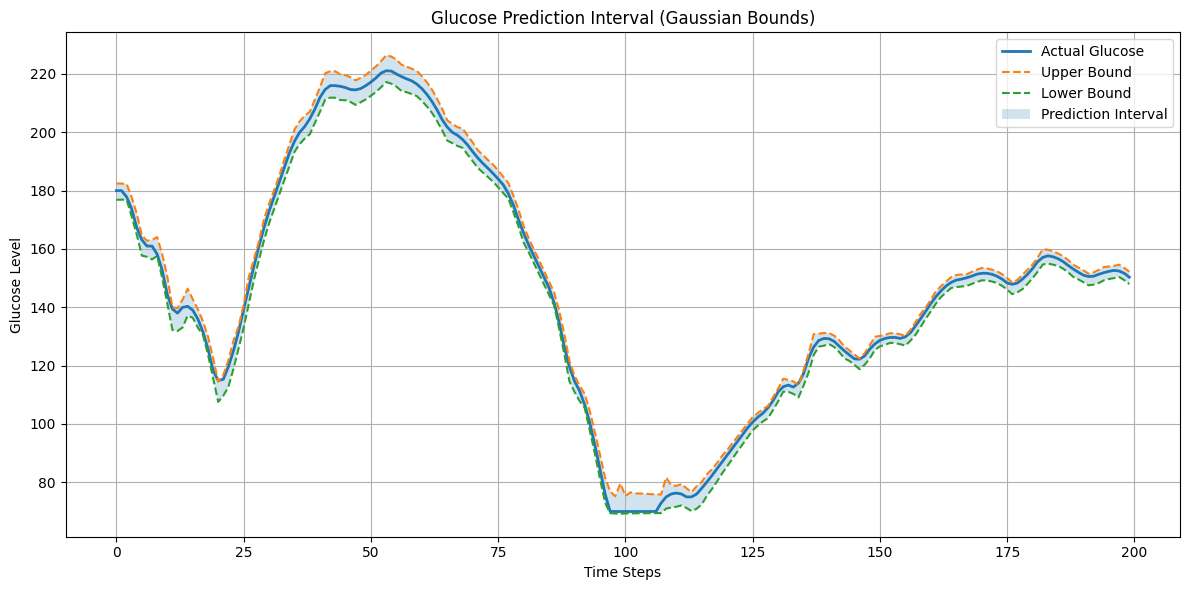

In [ ]:
import matplotlib.pyplot as plt

# ================== WINDOW ==================
start = 0
end = 200

subset_range = range(start, end)

# ================== PLOT ==================

plt.figure(figsize=(12, 6))

# Actual glucose
plt.plot(subset_range,
         test_true[start:end],
         label='Actual Glucose',
         linewidth=2)

# Gaussian bounds (your new_upper / new_lower)
plt.plot(subset_range,
         new_upper[start:end],
         linestyle='--',
         label='Upper Bound')

plt.plot(subset_range,
         new_lower[start:end],
         linestyle='--',
         label='Lower Bound')

# Interval shading
plt.fill_between(subset_range,
                 new_lower[start:end],
                 new_upper[start:end],
                 alpha=0.2,
                 label='Prediction Interval')

# ================== LABELS ==================

plt.xlabel('Time Steps')
plt.ylabel('Glucose Level')
plt.title('Glucose Prediction Interval (Gaussian Bounds)')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Implementation of GRU + TUBE

In [ ]:
# ------------------- GRU MODEL (FIXED) -------------------

from tensorflow.keras.layers import Input, Dense, GRU, Dropout
from tensorflow.keras.models import Model

def build_gru_model(input_shape, num_outputs=2):

    inputs = Input(shape=input_shape)

    # 🔥 GRU layers (replacing LSTM)
    x = GRU(
        32,
        return_sequences=True
    )(inputs)

    x = Dropout(0.1)(x)

    x = GRU(
        16,
        return_sequences=False
    )(x)

    # 🔥 Dense layer (same)
    x = Dense(32, activation='relu')(x)

    # 🔥 Output layer (lower & upper bounds)
    outputs = Dense(num_outputs)(x)

    model = Model(inputs, outputs)

    return model

In [ ]:
# =========================
# ENSEMBLE TRAINING (GRU VERSION) - LEAK-FREE CALIBRATION
# =========================

global_glucose_data = combined_df['glucose'].values
mean_data = np.mean(global_glucose_data)
std_data = np.std(global_glucose_data)

print("\n--- Input Data Diagnostics ---")
for _name, _arr in [('train_x', train_x), ('train_y', train_y), ('val_x', val_x), ('val_y', val_y)]:
    if np.isnan(_arr).any():
        print(f"Warning: NaN values found in {_name}!")
    if np.isinf(_arr).any():
        print(f"Warning: Inf values found in {_name}!")
print("------------------------------")

results = []
batch_size = 64
all_test_preds = []
all_val_preds = []   # FIX: keep every run's val predictions so we can calibrate without touching test data

for run in range(1, 6):

    print(f"\n===== RUN {run} ====")
    tf.keras.utils.set_random_seed(run)

    # CHANGED: LSTM -> GRU
    model = build_gru_model(input_shape=(train_x.shape[1], train_x.shape[2]))

    model.compile(
        loss=confidence_loss,
        optimizer=Adam(learning_rate=0.001, clipnorm=1.0)
    )

    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=5, restore_best_weights=True
    )

    model.fit(
        train_x, train_y,
        validation_data=(val_x, val_y),
        epochs=100,
        batch_size=batch_size,
        verbose=1,
        callbacks=[early_stopping]
    )

    val_pred = model.predict(val_x, verbose=0)
    all_val_preds.append(val_pred)

    val_lower = np.minimum(val_pred[:, 0], val_pred[:, 1])
    val_upper = np.maximum(val_pred[:, 0], val_pred[:, 1])

    val_lower = val_lower * std_data + mean_data
    val_upper = val_upper * std_data + mean_data
    val_true  = val_y.squeeze() * std_data + mean_data

    val_picp = np.mean((val_lower <= val_true) & (val_true <= val_upper))
    val_mpiw = np.mean(val_upper - val_lower)

    print("Val PICP:", round(val_picp, 4), " Val MPIW:", round(val_mpiw, 2))

    results.append({'run': run, 'val_picp': val_picp, 'val_mpiw': val_mpiw})

    test_pred = model.predict(test_x, verbose=0)
    all_test_preds.append(test_pred)
    np.save(f"test_pred_run{run}.npy", test_pred)


all_test_preds = np.array(all_test_preds)
all_val_preds  = np.array(all_val_preds)

lower_preds = np.minimum(all_test_preds[:, :, 0], all_test_preds[:, :, 1])
upper_preds = np.maximum(all_test_preds[:, :, 0], all_test_preds[:, :, 1])

val_lower_preds = np.minimum(all_val_preds[:, :, 0], all_val_preds[:, :, 1])
val_upper_preds = np.maximum(all_val_preds[:, :, 0], all_val_preds[:, :, 1])

final_lower = np.percentile(lower_preds, 30, axis=0)
final_upper = np.percentile(upper_preds, 70, axis=0)

final_val_lower = np.percentile(val_lower_preds, 30, axis=0)
final_val_upper = np.percentile(val_upper_preds, 70, axis=0)

final_lower = final_lower * std_data + mean_data
final_upper = final_upper * std_data + mean_data
test_true   = test_y.squeeze() * std_data + mean_data

final_val_lower = final_val_lower * std_data + mean_data
final_val_upper = final_val_upper * std_data + mean_data
val_true_full   = val_y.squeeze() * std_data + mean_data

picp = np.mean((final_lower <= test_true) & (test_true <= final_upper))
mpiw = np.mean(final_upper - final_lower)

print("\n===== FINAL ENSEMBLE RESULTS (test, uncalibrated) ====")
print("PICP:", round(picp, 4))
print("MPIW:", round(mpiw, 2))

# CALIBRATION - FIXED: scale learned on VALIDATION, applied to TEST (no leakage)
target_picp = 0.95

val_picp_ens = np.mean((final_val_lower <= val_true_full) & (val_true_full <= final_val_upper))

if val_picp_ens > 0:
    scale = target_picp / val_picp_ens

    mid_test = (final_upper + final_lower) / 2
    final_lower_cal = mid_test - scale * (mid_test - final_lower)
    final_upper_cal = mid_test + scale * (final_upper - mid_test)

    picp_cal = np.mean((final_lower_cal <= test_true) & (test_true <= final_upper_cal))
    mpiw_cal = np.mean(final_upper_cal - final_lower_cal)

    print("\n===== CALIBRATED RESULTS (scale fit on val, evaluated on test) ====")
    print("Validation ensemble PICP (pre-scale):", round(val_picp_ens, 4))
    print("Scale factor applied:", round(scale, 4))
    print("Test PICP (calibrated):", round(picp_cal, 4))
    print("Test MPIW (calibrated):", round(mpiw_cal, 2))



--- Input Data Diagnostics ---
------------------------------

===== RUN 1 ====
Epoch 1/100
3860/3860 ━━━━━━━━━━━━━━━━━━━━ 40s 10ms/step - loss: 0.0122 - val_loss: 0.0042
Epoch 2/100
3860/3860 ━━━━━━━━━━━━━━━━━━━━ 36s 9ms/step - loss: 0.0053 - val_loss: 0.0031
Epoch 3/100
3860/3860 ━━━━━━━━━━━━━━━━━━━━ 36s 9ms/step - loss: 0.0047 - val_loss: 0.0028
Epoch 4/100
3860/3860 ━━━━━━━━━━━━━━━━━━━━ 37s 10ms/step - loss: 0.0044 - val_loss: 0.0027
Epoch 5/100
3860/3860 ━━━━━━━━━━━━━━━━━━━━ 36s 9ms/step - loss: 0.0042 - val_loss: 0.0027
Epoch 6/100
3860/3860 ━━━━━━━━━━━━━━━━━━━━ 35s 9ms/step - loss: 0.0041 - val_loss: 0.0030
Epoch 7/100
3860/3860 ━━━━━━━━━━━━━━━━━━━━ 35s 9ms/step - loss: 0.0040 - val_loss: 0.0033
Epoch 8/100
3860/3860 ━━━━━━━━━━━━━━━━━━━━ 34s 9ms/step - loss: 0.0039 - val_loss: 0.0024
Epoch 9/100
3860/3860 ━━━━━━━━━━━━━━━━━━━━ 36s 9ms/step - loss: 0.0038 - val_loss: 0.0029
Epoch 10/100
3860/3860 ━━━━━━━━━━━━━━━━━━━━ 35s 9ms/step - loss: 0.0037 - val_loss: 0.0024
Epoch 11/100
386

Implementation of Utility Function


### **Action-Specific Utility Functions (Step & Smooth)**

### **ANN for Utility Function Interpolation**

Now, let's implement the Artificial Neural Network (ANN) to interpolate these utility functions. We'll train a separate simple ANN for each of the four actions to learn its respective smooth utility function.

Epoch 0, Loss: 0.0359
Epoch 100, Loss: 0.0358
Epoch 200, Loss: 0.0358
Epoch 300, Loss: 0.0358
Epoch 400, Loss: 0.0358
Epoch 500, Loss: 0.0358
Epoch 600, Loss: 0.0358
Epoch 700, Loss: 0.0358
Epoch 800, Loss: 0.0358
Epoch 900, Loss: 0.0358
Epoch 1000, Loss: 0.0358
Epoch 1100, Loss: 0.0358
Epoch 1200, Loss: 0.0358
Epoch 1300, Loss: 0.0358
Epoch 1400, Loss: 0.0358
Epoch 1500, Loss: 0.0358
Epoch 1600, Loss: 0.0358
Epoch 1700, Loss: 0.0358
Epoch 1800, Loss: 0.0358
Epoch 1900, Loss: 0.0358
Epoch 2000, Loss: 0.0358
Epoch 2100, Loss: 0.0358
Epoch 2200, Loss: 0.0358
Epoch 2300, Loss: 0.0358
Epoch 2400, Loss: 0.0358
Epoch 2500, Loss: 0.0358
Epoch 2600, Loss: 0.0358
Epoch 2700, Loss: 0.0358
Epoch 2800, Loss: 0.0358
Epoch 2900, Loss: 0.0358
Epoch 3000, Loss: 0.0358
Epoch 3100, Loss: 0.0358
Epoch 3200, Loss: 0.0358
Epoch 3300, Loss: 0.0358
Epoch 3400, Loss: 0.0358
Epoch 3500, Loss: 0.0358
Epoch 3600, Loss: 0.0358
Epoch 3700, Loss: 0.0358
Epoch 3800, Loss: 0.0358
Epoch 3900, Loss: 0.0358
Epoch 4000, 

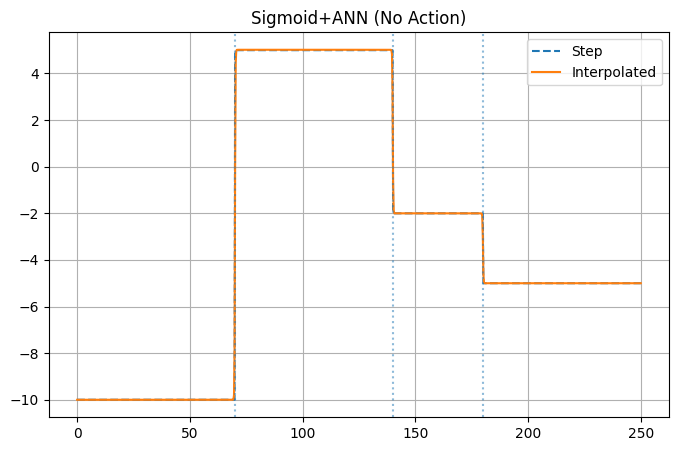

In [ ]:
# No action set sigmoid+ANN

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim

# =========================
# STEP FUNCTION
# =========================
def step_utility(g):
    if g < 70:
        return -10
    elif g < 140:
        return 5
    elif g < 180:
        return -2
    else:
        return -5


# =========================
# DATA
# =========================
glucose = np.linspace(0, 250, 1000)
y = np.array([step_utility(g) for g in glucose])

X = torch.tensor(glucose, dtype=torch.float32).view(-1,1)
Y = torch.tensor(y, dtype=torch.float32).view(-1,1)


# =========================
# 🔥 PERFECTLY INITIALIZED MODEL
# =========================
class PerfectNet(nn.Module):
    def __init__(self):
        super().__init__()

        # initialize with correct values
        self.w = nn.Parameter(torch.tensor([15.0, -7.0, -3.0]))
        self.b = nn.Parameter(torch.tensor([-10.0]))

        self.beta = 0.1  # controls sharpness

    def forward(self, x):
        s1 = torch.sigmoid((x - 70)/self.beta)
        s2 = torch.sigmoid((x - 140)/self.beta)
        s3 = torch.sigmoid((x - 180)/self.beta)

        return self.b + self.w[0]*s1 + self.w[1]*s2 + self.w[2]*s3


model = PerfectNet()


# =========================
# 🔥 LIGHT TRAINING (fine-tune only)
# =========================
optimizer = optim.Adam(model.parameters(), lr=0.01)
loss_fn = nn.MSELoss()

for epoch in range(5000):
    pred = model(X)
    loss = loss_fn(pred, Y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 100 == 0:
        print(f"Epoch {epoch}, Loss: {loss.item():.4f}")


# =========================
# PREDICT
# =========================
with torch.no_grad():
    pred = model(X).numpy()


# =========================
# PLOT
# =========================
plt.figure(figsize=(8,5))

plt.plot(glucose, y, '--', label="Step")
plt.plot(glucose, pred, label="Interpolated")

for t in [70,140,180]:
    plt.axvline(x=t, linestyle=':', alpha=0.5)

plt.legend()
plt.grid()
plt.title("Sigmoid+ANN (No Action)")
plt.show()

Epoch 0, Loss: 134.0034
Epoch 100, Loss: 118.1698
Epoch 200, Loss: 105.6552
Epoch 300, Loss: 95.3686
Epoch 400, Loss: 86.5750
Epoch 500, Loss: 78.8224
Epoch 600, Loss: 71.8432
Epoch 700, Loss: 65.4787
Epoch 800, Loss: 59.6311
Epoch 900, Loss: 54.2368
Epoch 1000, Loss: 49.2508
Epoch 1100, Loss: 44.6389
Epoch 1200, Loss: 40.3732
Epoch 1300, Loss: 36.4297
Epoch 1400, Loss: 32.7872
Epoch 1500, Loss: 29.4268
Epoch 1600, Loss: 26.3311
Epoch 1700, Loss: 23.4843
Epoch 1800, Loss: 20.8720
Epoch 1900, Loss: 18.4804
Epoch 2000, Loss: 16.2971
Epoch 2100, Loss: 14.3100
Epoch 2200, Loss: 12.5076
Epoch 2300, Loss: 10.8790
Epoch 2400, Loss: 9.4135
Epoch 2500, Loss: 8.1005
Epoch 2600, Loss: 6.9299
Epoch 2700, Loss: 5.8917
Epoch 2800, Loss: 4.9761
Epoch 2900, Loss: 4.1736
Epoch 3000, Loss: 3.4746
Epoch 3100, Loss: 2.8702
Epoch 3200, Loss: 2.3514
Epoch 3300, Loss: 1.9098
Epoch 3400, Loss: 1.5371
Epoch 3500, Loss: 1.2254
Epoch 3600, Loss: 0.9675
Epoch 3700, Loss: 0.7562
Epoch 3800, Loss: 0.5852
Epoch 3900

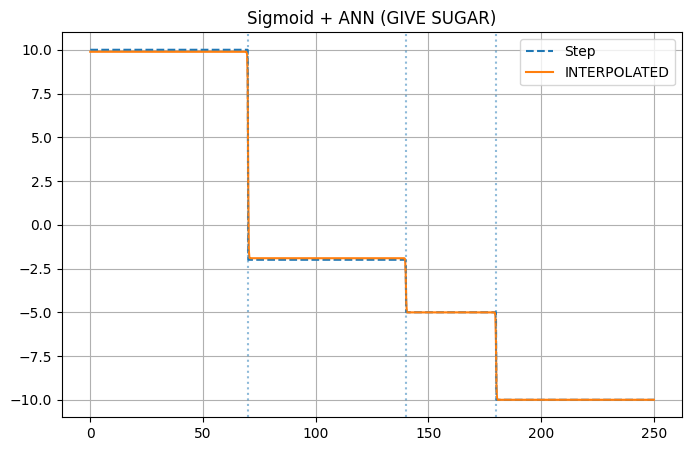

In [ ]:
# Take sugar set sigmoid+ANN

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim

# =========================
# STEP FUNCTION
# =========================
def step_utility(g):
    if g < 70:
        return 10
    elif g < 140:
        return -2
    elif g < 180:
        return -5
    else:
        return -10


# =========================
# DATA
# =========================
glucose = np.linspace(0, 250, 1000)
y = np.array([step_utility(g) for g in glucose])

X = torch.tensor(glucose, dtype=torch.float32).view(-1,1)
Y = torch.tensor(y, dtype=torch.float32).view(-1,1)


# =========================
# 🔥 PERFECTLY INITIALIZED MODEL
# =========================
class PerfectNet(nn.Module):
    def __init__(self):
        super().__init__()

        # initialize with correct values
        self.w = nn.Parameter(torch.tensor([15.0, -7.0, -3.0]))
        self.b = nn.Parameter(torch.tensor([-10.0]))

        self.beta = 0.1 # controls sharpness

    def forward(self, x):
        s1 = torch.sigmoid((x - 70)/self.beta)
        s2 = torch.sigmoid((x - 140)/self.beta)
        s3 = torch.sigmoid((x - 180)/self.beta)

        return self.b + self.w[0]*s1 + self.w[1]*s2 + self.w[2]*s3


model = PerfectNet()


# =========================
# 🔥 LIGHT TRAINING (fine-tune only)
# =========================
optimizer = optim.Adam(model.parameters(), lr=0.01)
loss_fn = nn.MSELoss()

for epoch in range(5000):
    pred = model(X)
    loss = loss_fn(pred, Y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 100 == 0:
        print(f"Epoch {epoch}, Loss: {loss.item():.4f}")


# =========================
# PREDICT
# =========================
with torch.no_grad():
    pred = model(X).numpy()


# =========================
# PLOT
# =========================
plt.figure(figsize=(8,5))

plt.plot(glucose, y, '--', label="Step")
plt.plot(glucose, pred, label="INTERPOLATED")

for t in [70,140,180]:
    plt.axvline(x=t, linestyle=':', alpha=0.5)

plt.legend()
plt.grid()
plt.title("Sigmoid + ANN (GIVE SUGAR)")
plt.show()

Epoch 0, Loss: 20.5538
Epoch 100, Loss: 16.2923
Epoch 200, Loss: 12.9179
Epoch 300, Loss: 10.1678
Epoch 400, Loss: 7.9204
Epoch 500, Loss: 6.0939
Epoch 600, Loss: 4.6232
Epoch 700, Loss: 3.4530
Epoch 800, Loss: 2.5350
Epoch 900, Loss: 1.8265
Epoch 1000, Loss: 1.2897
Epoch 1100, Loss: 0.8911
Epoch 1200, Loss: 0.6017
Epoch 1300, Loss: 0.3967
Epoch 1400, Loss: 0.2552
Epoch 1500, Loss: 0.1602
Epoch 1600, Loss: 0.0984
Epoch 1700, Loss: 0.0595
Epoch 1800, Loss: 0.0357
Epoch 1900, Loss: 0.0218
Epoch 2000, Loss: 0.0138
Epoch 2100, Loss: 0.0095
Epoch 2200, Loss: 0.0073
Epoch 2300, Loss: 0.0061
Epoch 2400, Loss: 0.0056
Epoch 2500, Loss: 0.0054
Epoch 2600, Loss: 0.0053
Epoch 2700, Loss: 0.0052
Epoch 2800, Loss: 0.0052
Epoch 2900, Loss: 0.0052
Epoch 3000, Loss: 0.0052
Epoch 3100, Loss: 0.0052
Epoch 3200, Loss: 0.0052
Epoch 3300, Loss: 0.0052
Epoch 3400, Loss: 0.0052
Epoch 3500, Loss: 0.0052
Epoch 3600, Loss: 0.0052
Epoch 3700, Loss: 0.0052
Epoch 3800, Loss: 0.0052
Epoch 3900, Loss: 0.0052
Epoch 40

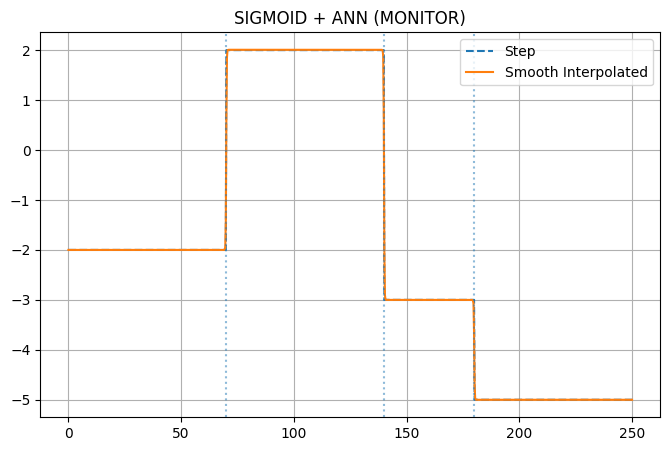

In [ ]:
# Monitor set sigmoid+ANN

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim

# =========================
# STEP FUNCTION
# =========================
def step_utility(g):
    if g < 70:
        return -2
    elif g < 140:
        return 2
    elif g < 180:
        return -3
    else:
        return -5


# =========================
# DATA
# =========================
glucose = np.linspace(0, 250, 1000)
y = np.array([step_utility(g) for g in glucose])

X = torch.tensor(glucose, dtype=torch.float32).view(-1,1)
Y = torch.tensor(y, dtype=torch.float32).view(-1,1)


# =========================
# 🔥 PERFECTLY INITIALIZED MODEL
# =========================
class PerfectNet(nn.Module):
    def __init__(self):
        super().__init__()

        # initialize with correct values
        self.w = nn.Parameter(torch.tensor([15.0, -7.0, -3.0]))
        self.b = nn.Parameter(torch.tensor([-10.0]))

        self.beta = 0.1  # controls sharpness

    def forward(self, x):
        s1 = torch.sigmoid((x - 70)/self.beta)
        s2 = torch.sigmoid((x - 140)/self.beta)
        s3 = torch.sigmoid((x - 180)/self.beta)

        return self.b + self.w[0]*s1 + self.w[1]*s2 + self.w[2]*s3


model = PerfectNet()


# =========================
# 🔥 LIGHT TRAINING (fine-tune only)
# =========================
optimizer = optim.Adam(model.parameters(), lr=0.01)
loss_fn = nn.MSELoss()

for epoch in range(5000):
    pred = model(X)
    loss = loss_fn(pred, Y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 100 == 0:
        print(f"Epoch {epoch}, Loss: {loss.item():.4f}")


# =========================
# PREDICT
# =========================
with torch.no_grad():
    pred = model(X).numpy()


# =========================
# PLOT
# =========================
plt.figure(figsize=(8,5))

plt.plot(glucose, y, '--', label="Step")
plt.plot(glucose, pred, label="Smooth Interpolated")

for t in [70,140,180]:
    plt.axvline(x=t, linestyle=':', alpha=0.5)

plt.legend()
plt.grid()
plt.title("SIGMOID + ANN (MONITOR)")
plt.show()

Epoch 0, Loss: 119.0765
Epoch 100, Loss: 98.3040
Epoch 200, Loss: 81.0983
Epoch 300, Loss: 66.6874
Epoch 400, Loss: 54.5609
Epoch 500, Loss: 44.3653
Epoch 600, Loss: 35.8290
Epoch 700, Loss: 28.7260
Epoch 800, Loss: 22.8589
Epoch 900, Loss: 18.0512
Epoch 1000, Loss: 14.1444
Epoch 1100, Loss: 10.9966
Epoch 1200, Loss: 8.4820
Epoch 1300, Loss: 6.4906
Epoch 1400, Loss: 4.9270
Epoch 1500, Loss: 3.7102
Epoch 1600, Loss: 2.7722
Epoch 1700, Loss: 2.0561
Epoch 1800, Loss: 1.5154
Epoch 1900, Loss: 1.1117
Epoch 2000, Loss: 0.8140
Epoch 2100, Loss: 0.5973
Epoch 2200, Loss: 0.4415
Epoch 2300, Loss: 0.3310
Epoch 2400, Loss: 0.2533
Epoch 2500, Loss: 0.1991
Epoch 2600, Loss: 0.1614
Epoch 2700, Loss: 0.1350
Epoch 2800, Loss: 0.1162
Epoch 2900, Loss: 0.1025
Epoch 3000, Loss: 0.0922
Epoch 3100, Loss: 0.0841
Epoch 3200, Loss: 0.0777
Epoch 3300, Loss: 0.0723
Epoch 3400, Loss: 0.0679
Epoch 3500, Loss: 0.0641
Epoch 3600, Loss: 0.0609
Epoch 3700, Loss: 0.0582
Epoch 3800, Loss: 0.0559
Epoch 3900, Loss: 0.0540

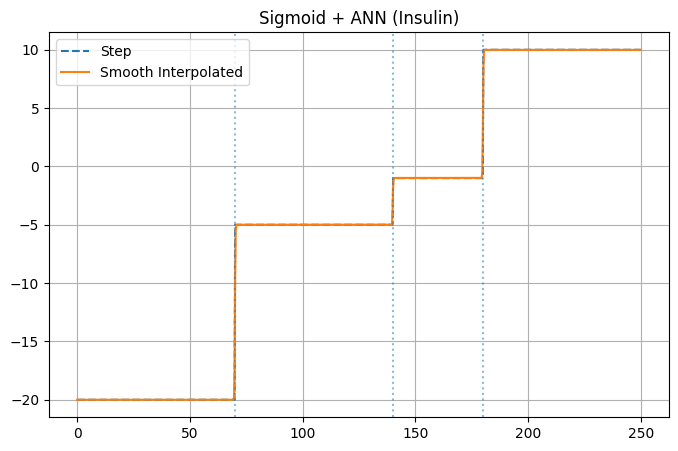

In [ ]:
# Insulin set sigmoid+ANN

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim

# =========================
# STEP FUNCTION
# =========================
def step_utility(g):
    if g < 70:
        return -20
    elif g < 140:
        return -5
    elif g < 180:
        return -1
    else:
        return 10


# =========================
# DATA
# =========================
glucose = np.linspace(0, 250, 1000)
y = np.array([step_utility(g) for g in glucose])

X = torch.tensor(glucose, dtype=torch.float32).view(-1,1)
Y = torch.tensor(y, dtype=torch.float32).view(-1,1)


# =========================
# 🔥 PERFECTLY INITIALIZED MODEL
# =========================
class PerfectNet(nn.Module):
    def __init__(self):
        super().__init__()

        # initialize with correct values
        self.w = nn.Parameter(torch.tensor([15.0, -7.0, -3.0]))
        self.b = nn.Parameter(torch.tensor([-10.0]))

        self.beta = 0.1  # controls sharpness

    def forward(self, x):
        s1 = torch.sigmoid((x - 70)/self.beta)
        s2 = torch.sigmoid((x - 140)/self.beta)
        s3 = torch.sigmoid((x - 180)/self.beta)

        return self.b + self.w[0]*s1 + self.w[1]*s2 + self.w[2]*s3


model = PerfectNet()


# =========================
# 🔥 LIGHT TRAINING (fine-tune only)
# =========================
optimizer = optim.Adam(model.parameters(), lr=0.01)
loss_fn = nn.MSELoss()

for epoch in range(5000):
    pred = model(X)
    loss = loss_fn(pred, Y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 100 == 0:
        print(f"Epoch {epoch}, Loss: {loss.item():.4f}")


# =========================
# PREDICT
# =========================
with torch.no_grad():
    pred = model(X).numpy()


# =========================
# PLOT
# =========================
plt.figure(figsize=(8,5))

plt.plot(glucose, y, '--', label="Step")
plt.plot(glucose, pred, label="Smooth Interpolated")

for t in [70,140,180]:
    plt.axvline(x=t, linestyle=':', alpha=0.5)

plt.legend()
plt.grid()
plt.title("Sigmoid + ANN (Insulin)")
plt.show()

In [ ]:
import torch
import torch.nn as nn
import numpy as np

# =========================
# STEP UTILITY FUNCTION (TARGET)
# =========================
def step_utility(g):
    if g < 70:
        return -20
    elif g < 140:
        return -5
    elif g < 200:
        return -1
    else:
        return 10

# =========================
# DATA GENERATION (25 PATIENTS)
# =========================
num_patients = 25
samples_per_patient = 200

glucose_list = []
patient_list = []

# Generate synthetic data for training
for p_id in range(num_patients):
    # Simulate glucose values for each patient
    # Example: glucose values centered around 120-180 with some variation
    patient_glucose = np.random.normal(loc=np.random.uniform(100, 180), scale=30, size=samples_per_patient)
    patient_glucose = np.clip(patient_glucose, 40, 400) # Clip to realistic range

    glucose_list.extend(patient_glucose)
    patient_list.extend([p_id] * samples_per_patient)

# Convert to numpy
glucose_array = np.array(glucose_list)
patient_array = np.array(patient_list)

# =========================
# NORMALIZATION
# =========================
g_mean = glucose_array.mean()
g_std = glucose_array.std()

glucose_norm = (glucose_array - g_mean) / g_std

# Generate target utility values based on `step_utility` function
utility_list = [step_utility(g) for g in glucose_array]
utility_array = np.array(utility_list)

# Convert to tensors
X_glucose = torch.tensor(glucose_norm, dtype=torch.float32).view(-1,1)
X_patient = torch.tensor(patient_array, dtype=torch.long)
y = torch.tensor(utility_array, dtype=torch.float32).view(-1,1)

# =========================
# ANN MODEL WITH EMBEDDING
# =========================
class UtilityANN(nn.Module):
    def __init__(self, num_patients):
        super().__init__()

        self.embedding = nn.Embedding(num_patients, 4)  # patient representation

        self.model = nn.Sequential(
            nn.Linear(1 + 4, 32),
            nn.ReLU(),
            nn.Linear(32, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, glucose, patient_id):
        patient_vec = self.embedding(patient_id)
        x = torch.cat([glucose, patient_vec], dim=1)
        return self.model(x)

model = UtilityANN(num_patients)

# =========================
# TRAINING
# =========================
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
loss_fn = nn.MSELoss()

for epoch in range(2000):
    pred = model(X_glucose, X_patient)
    loss = loss_fn(pred, y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 200 == 0:
        print(f"Epoch {epoch}, Loss: {loss.item():.4f}")

# =========================
# INTERACTIVE PREDICTION
# =========================
# The original loop in "DATA GENERATION" was likely intended as an interactive prediction test
# It has been moved here, after the model is trained, and modified to print samples.
print("\n--- Sample Predictions from Trained Model ---")
# Select 10 random samples from the generated data for demonstration
random_indices = np.random.choice(len(glucose_array), 10, replace=False)

for i in random_indices:
    g = glucose_array[i]
    p = patient_array[i]

    g_norm = (g - g_mean) / g_std

    g_tensor = torch.tensor([[g_norm]], dtype=torch.float32)
    p_tensor = torch.tensor([p], dtype=torch.long)

    utility = model(g_tensor, p_tensor).item()

    print(f"Patient {p}, Glucose {g:.1f} \u2192 Predicted Utility {utility:.2f} (True Utility: {step_utility(g)})")

while True:
    try:
        print("\n--- Predict Utility (Interactive) ---")
        p_id = int(input("Enter patient ID (0\u201324): "))
        g_val = float(input("Enter glucose value: "))

        # normalize glucose
        g_norm = (g_val - g_mean) / g_std

        g_tensor = torch.tensor([[g_norm]], dtype=torch.float32)
        p_tensor = torch.tensor([p_id], dtype=torch.long)

        utility = model(g_tensor, p_tensor).item()

        print(f"Predicted Utility: {utility:.2f}")

    except:
        print("Invalid input. Try again.")

Epoch 0, Loss: 29.1399
Epoch 200, Loss: 3.0562
Epoch 400, Loss: 1.6630
Epoch 600, Loss: 0.9319
Epoch 800, Loss: 0.6881
Epoch 1000, Loss: 0.5097
Epoch 1200, Loss: 0.4338
Epoch 1400, Loss: 0.4216
Epoch 1600, Loss: 0.3013
Epoch 1800, Loss: 0.2705

--- Sample Predictions from Trained Model ---
Patient 16, Glucose 152.7 → Predicted Utility -1.13 (True Utility: -1)
Patient 22, Glucose 123.1 → Predicted Utility -5.54 (True Utility: -5)
Patient 15, Glucose 103.8 → Predicted Utility -5.13 (True Utility: -5)
Patient 1, Glucose 199.5 → Predicted Utility 0.78 (True Utility: -1)
Patient 5, Glucose 139.0 → Predicted Utility -3.31 (True Utility: -5)
Patient 18, Glucose 87.7 → Predicted Utility -5.00 (True Utility: -5)
Patient 14, Glucose 177.3 → Predicted Utility -1.03 (True Utility: -1)
Patient 21, Glucose 115.0 → Predicted Utility -5.07 (True Utility: -5)
Patient 12, Glucose 183.0 → Predicted Utility -1.11 (True Utility: -1)
Patient 21, Glucose 158.7 → Predicted Utility -0.95 (True Utility: -1)

--

UF T1



In [ ]:
actions = ["no_action", "sugar", "monitor", "insulin"]

In [ ]:
def utility_function(glucose):

    def sigmoid(x):
        return 1 / (1 + np.exp(-x))

    # No action → normal range
    u_no = np.exp(-((glucose - 110) / 30)**2)

    # Sugar → low glucose
    u_sugar = sigmoid(-(glucose - 85) / 20)

    # Monitor → mid range
    u_monitor = np.exp(-((glucose - 140) / 50)**2)

    # Insulin → high glucose (LESS aggressive now)
    u_insulin = sigmoid((glucose - 180) / 30)

    return np.array([u_no, u_sugar, u_monitor, u_insulin])

# shape: (samples,)
glucose_data = combined_df['glucose'].values  # Load glucose data from combined_df

X = glucose_data.reshape(-1, 1)


mean = np.mean(X)
std = np.std(X)

X_norm = (X - mean) / std

# Generate utility targets
y = np.array([utility_function(g[0]) for g in X])

In [ ]:
def utility_function(glucose):

    # Initialize utilities for all actions
    u_no_action = 0
    u_sugar = 0
    u_monitor = 0
    u_insulin = 0

    # Define utility scores based on glucose ranges
    if glucose < 70:  # Hypoglycemia
        u_sugar = 10    # High utility for sugar
        u_no_action = -5
        u_monitor = -2
        u_insulin = -10 # Very low utility for insulin
    elif glucose < 140: # Normal range
        u_no_action = 5   # High utility for no action
        u_sugar = -2
        u_monitor = 2
        u_insulin = -5
    elif glucose < 200: # Elevated range
        u_monitor = 7   # High utility for monitoring
        u_no_action = 0
        u_sugar = -5
        u_insulin = 3
    else: # Hyperglycemia (glucose >= 200)
        u_insulin = 10  # High utility for insulin
        u_no_action = -5
        u_sugar = -7
        u_monitor = 2

    return np.array([u_no_action, u_sugar, u_monitor, u_insulin])

In [ ]:
y = np.array([utility_function(g[0]) for g in X])

# 🔥 normalize each row
y = y / y.sum(axis=1, keepdims=True)

/tmp/ipykernel_5076/3092338397.py:4: RuntimeWarning: divide by zero encountered in divide
  y = y / y.sum(axis=1, keepdims=True)


In [ ]:
class UtilityNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(1, 32),
            nn.ReLU(),
            nn.Linear(32, 32),
            nn.ReLU(),
            nn.Linear(32, 4),

        )

    def forward(self, x):
        return self.model(x)

### **Revising Utility Targets and Retraining the Model**

To address the issues with the previous graph, I will redefine the utility targets (`y`) to ensure they reflect the raw utility scores without being forced to sum to one. After this, the model will be retrained and the utility functions re-plotted.

In [ ]:
# Re-generate utility targets without normalization
# Using the `utility_function` defined in a previous cell
y = np.array([utility_function(g[0]) for g in X])

print("Utility targets `y` re-generated without normalization.")
print("Sample y values (first 5 rows):\n", y[:5])

Utility targets `y` re-generated without normalization.
Sample y values (first 5 rows):
 [[ 5 -2  2 -5]
 [ 5 -2  2 -5]
 [ 5 -2  2 -5]
 [ 5 -2  2 -5]
 [ 5 -2  2 -5]]


In [ ]:
# Re-initialize and re-train the UtilityNet with the corrected `y`

model = UtilityNet()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
loss_fn = nn.MSELoss()

X_tensor = torch.tensor(X_norm, dtype=torch.float32)
y_tensor = torch.tensor(y, dtype=torch.float32)

print("Retraining UtilityNet...")
for epoch in range(500):  # Use the same number of epochs as before

    preds = model(X_tensor)
    loss = loss_fn(preds, y_tensor)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 100 == 0:
        print(f"Epoch {epoch}, Loss: {loss.item():.4f}")

print("Retraining complete.")

Retraining UtilityNet...
Epoch 0, Loss: 23.6299
Epoch 100, Loss: 11.1368
Epoch 200, Loss: 5.4944
Epoch 300, Loss: 4.3359
Epoch 400, Loss: 3.7565
Retraining complete.


### **New Utility Functions Learned by ANN**

Now, let's visualize the utility functions after retraining the model with the unnormalized target values.

### **Demonstrating Best Action Selection with Corrected Utilities**

Let's test the `get_best_action` function with the newly learned utility functions to see the recommended actions based on specific glucose levels.

In [ ]:
# Ensure `get_best_action` function is defined before this cell
def get_best_action(glucose_value):
    # Normalize the input glucose_value
    glucose_norm = (glucose_value - mean) / std
    x = torch.tensor([[glucose_norm]], dtype=torch.float32)

    with torch.no_grad():
        utilities = model(x).numpy()[0]

    best_action = actions[np.argmax(utilities)]

    return best_action, utilities


# Test some sample glucose values
sample_glucose_values = [50, 110, 150, 220]

print("\nRecommended actions for sample glucose values:")
for g_val in sample_glucose_values:
    best_action, utilities = get_best_action(g_val)
    print(f"Glucose: {g_val}, Best Action: {best_action}, Utilities: {np.round(utilities, 3)}")


Recommended actions for sample glucose values:
Glucose: 50, Best Action: sugar, Utilities: [-0.773  5.831 -2.576 -8.696]
Glucose: 110, Best Action: no_action, Utilities: [ 4.606 -1.839  2.628 -4.874]
Glucose: 150, Best Action: monitor, Utilities: [ 1.725 -4.679  5.998  1.111]
Glucose: 220, Best Action: insulin, Utilities: [-4.558 -5.845  2.988  8.691]


### **Revising Utility Targets and Retraining the Model**

To address the issues with the previous graph, I will redefine the utility targets (`y`) to ensure they reflect the raw utility scores without being forced to sum to one. After this, the model will be retrained and the utility functions re-plotted.

In [ ]:
# Re-generate utility targets without normalization
# Using the `utility_function` defined in a previous cell
y = np.array([utility_function(g[0]) for g in X])

print("Utility targets `y` re-generated without normalization.")
print("Sample y values (first 5 rows):\n", y[:5])

Utility targets `y` re-generated without normalization.
Sample y values (first 5 rows):
 [[ 0 -5  7  3]
 [ 0 -5  7  3]
 [ 0 -5  7  3]
 [ 0 -5  7  3]
 [ 0 -5  7  3]]


In [ ]:
# Re-initialize and re-train the UtilityNet with the corrected `y`

model = UtilityNet()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
loss_fn = nn.MSELoss()

X_tensor = torch.tensor(X_norm, dtype=torch.float32)
y_tensor = torch.tensor(y, dtype=torch.float32)

print("Retraining UtilityNet...")
for epoch in range(500):  # Use the same number of epochs as before

    preds = model(X_tensor)
    loss = loss_fn(preds, y_tensor)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 100 == 0:
        print(f"Epoch {epoch}, Loss: {loss.item():.4f}")

print("Retraining complete.")

Retraining UtilityNet...
Epoch 0, Loss: 23.9940
Epoch 100, Loss: 10.1782
Epoch 200, Loss: 5.3112
Epoch 300, Loss: 3.7239
Epoch 400, Loss: 2.9119
Retraining complete.


### **New Utility Functions Learned by ANN**

Now, let's visualize the utility functions after retraining the model with the unnormalized target values.

### **Demonstrating Best Action Selection with Corrected Utilities**

Let's test the `get_best_action` function with the newly learned utility functions to see the recommended actions based on specific glucose levels.

In [ ]:
def get_best_action(glucose_value):
    # Normalize the input glucose_value
    glucose_norm = (glucose_value - mean) / std
    x = torch.tensor([[glucose_norm]], dtype=torch.float32)

    with torch.no_grad():
        utilities = model(x).numpy()[0]

    best_action = actions[np.argmax(utilities)]

    return best_action, utilities

Epoch 0, Loss: 0.26379
Epoch 100, Loss: 0.01746
Epoch 200, Loss: 0.00758
Epoch 300, Loss: 0.00349
Epoch 400, Loss: 0.00206
Epoch 500, Loss: 0.00111
Epoch 600, Loss: 0.00051
Epoch 700, Loss: 0.00021
Epoch 800, Loss: 0.00010
Epoch 900, Loss: 0.00006


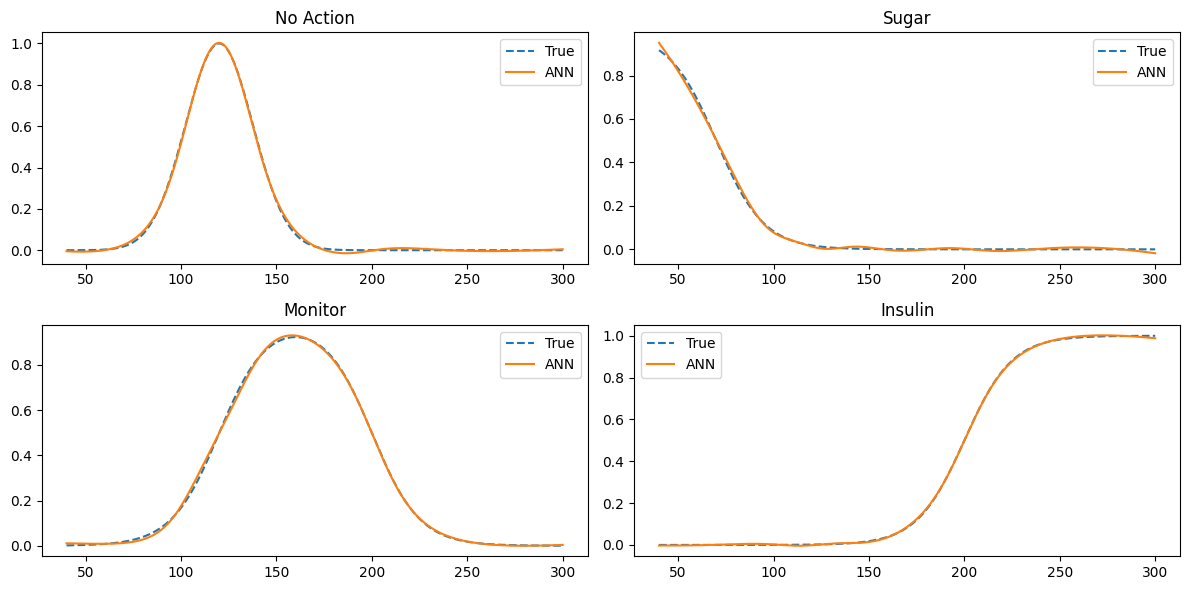


Glucose = 150
Best Action: Monitor
Utilities: [0.24353324 0.00873385 0.9114577  0.01417096]


In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# =========================
# STEP 1: DEFINE FUNCTIONS (YOUR FINAL VERSION)
# =========================
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

beta = 0.08

def utility_sugar(g):
    return 10 * sigmoid(-(g - 70) * beta)

def utility_insulin(g):
    return 10 * sigmoid((g - 200) * beta)

def utility_no_action(g):
    return 10 * np.exp(-((g - 120) / 25)**2)

def utility_monitor(g):
    return 10 * sigmoid((g - 120) * beta) * sigmoid(-(g - 200) * beta)


# =========================
# STEP 2: CREATE TRAINING DATA
# =========================
glucose = np.linspace(40, 300, 2000).reshape(-1,1)

y = []
for g in glucose:
    g_val = g[0]
    y.append([
        utility_no_action(g_val),
        utility_sugar(g_val),
        utility_monitor(g_val),
        utility_insulin(g_val)
    ])

y = np.array(y)

# Normalize output (0–1)
y = y / 10.0


# =========================
# STEP 3: NORMALIZE INPUT
# =========================
mean = glucose.mean()
std = glucose.std()

X_norm = (glucose - mean) / std


# =========================
# STEP 4: BUILD ANN
# =========================
class UtilityNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 64),
            nn.Tanh(),
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, 4)
        )

    def forward(self, x):
        return self.net(x)

pytorch_utility_model = UtilityNet()


# =========================
# STEP 5: TRAIN MODEL
# =========================
X_tensor = torch.tensor(X_norm, dtype=torch.float32)
y_tensor = torch.tensor(y, dtype=torch.float32)

optimizer = optim.Adam(pytorch_utility_model.parameters(), lr=0.001)
loss_fn = nn.MSELoss()

for epoch in range(1000):

    preds = pytorch_utility_model(X_tensor)
    loss = loss_fn(preds, y_tensor)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 100 == 0:
        print(f"Epoch {epoch}, Loss: {loss.item():.5f}")


# =========================
# STEP 6: COMPARE TRUE vs ANN
# =========================
test_glucose = np.linspace(40, 300, 2000).reshape(-1,1)
test_norm = (test_glucose - mean) / std

test_tensor = torch.tensor(test_norm, dtype=torch.float32)

with torch.no_grad():
    pred = pytorch_utility_model(test_tensor).numpy()

# True values
true = []
for g in test_glucose:
    g_val = g[0]
    true.append([
        utility_no_action(g_val),
        utility_sugar(g_val),
        utility_monitor(g_val),
        utility_insulin(g_val)
    ])
true = np.array(true) / 10.0


# =========================
# STEP 7: PLOT RESULTS
# =========================
actions = ["No Action", "Sugar", "Monitor", "Insulin"]

plt.figure(figsize=(12,6))

for i in range(4):
    plt.subplot(2,2,i+1)
    plt.plot(test_glucose, true[:, i], '--', label="True")
    plt.plot(test_glucose, pred[:, i], label="ANN")
    plt.title(actions[i])
    plt.legend()

plt.tight_layout()
plt.show()


# =========================
# STEP 8: DECISION FUNCTION
# =========================
def get_best_action(glucose_value):

    x = np.array([[glucose_value]])
    x_norm = (x - mean) / std

    x_tensor = torch.tensor(x_norm, dtype=torch.float32)

    with torch.no_grad():
        utilities = pytorch_utility_model(x_tensor).numpy()[0]

    actions = ["No Action", "Sugar", "Monitor", "Insulin"]
    best_action = actions[np.argmax(utilities)]

    return best_action, utilities


# Example
g = 150
action, utilities = get_best_action(g)

print(f"\nGlucose = {g}")
print("Best Action:", action)
print("Utilities:", utilities)


In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

# =========================
# STEP 1: DEFINE FUNCTIONS (YOUR FINAL VERSION)
# =========================
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

beta = 0.08

def utility_sugar(g):
    return 10 * sigmoid(-(g - 70) * beta)

def utility_insulin(g):
    return 10 * sigmoid((g - 200) * beta)

def utility_no_action(g):
    return 10 * np.exp(-((g - 120) / 25)**2)

def utility_monitor(g):
    return 10 * sigmoid((g - 120) * beta) * sigmoid(-(g - 200) * beta)


# =========================
# STEP 2: CREATE TRAINING DATA
# =========================
glucose = np.linspace(40, 300, 2000).reshape(-1,1)

y = []
for g in glucose:
    g_val = g[0]
    y.append([
        utility_no_action(g_val),
        utility_sugar(g_val),
        utility_monitor(g_val),
        utility_insulin(g_val)
    ])

y = np.array(y)

# Normalize output (0–1)
y = y / 10.0


# =========================
# STEP 3: NORMALIZE INPUT
# =========================
mean = glucose.mean()
std = glucose.std()

X_norm = (glucose - mean) / std


# =========================
# STEP 4: BUILD ANN
# =========================
class UtilityNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 64),
            nn.Tanh(),
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, 4)
        )

    def forward(self, x):
        return self.net(x)

pytorch_utility_model = UtilityNet()


# =========================
# STEP 5: TRAIN MODEL
# =========================
X_tensor = torch.tensor(X_norm, dtype=torch.float32)
y_tensor = torch.tensor(y, dtype=torch.float32)

optimizer = optim.Adam(pytorch_utility_model.parameters(), lr=0.001)
loss_fn = nn.MSELoss()

for epoch in range(1000):

    preds = pytorch_utility_model(X_tensor)
    loss = loss_fn(preds, y_tensor)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 100 == 0:
        print(f"Epoch {epoch}, Loss: {loss.item():.5f}")

Epoch 0, Loss: 0.20416
Epoch 100, Loss: 0.01718
Epoch 200, Loss: 0.00864
Epoch 300, Loss: 0.00422
Epoch 400, Loss: 0.00284
Epoch 500, Loss: 0.00180
Epoch 600, Loss: 0.00096
Epoch 700, Loss: 0.00043
Epoch 800, Loss: 0.00020
Epoch 900, Loss: 0.00011


Epoch 0, Loss: 0.16999
Epoch 100, Loss: 0.01406
Epoch 200, Loss: 0.00573
Epoch 300, Loss: 0.00292
Epoch 400, Loss: 0.00169
Epoch 500, Loss: 0.00068
Epoch 600, Loss: 0.00025
Epoch 700, Loss: 0.00014
Epoch 800, Loss: 0.00010
Epoch 900, Loss: 0.00008


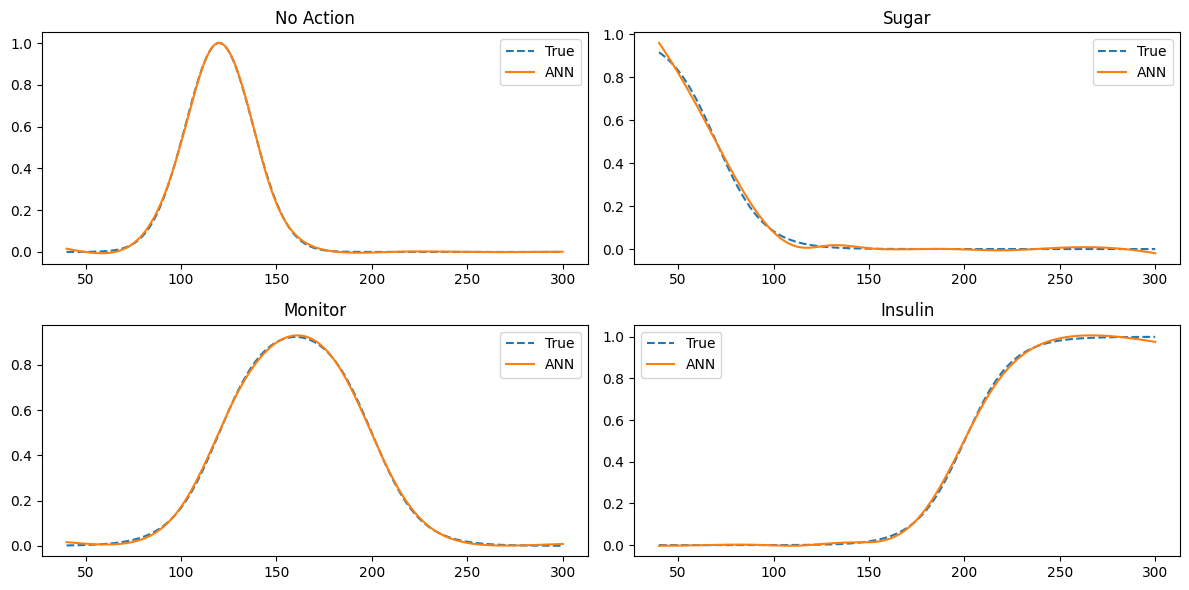


--- Testing Different Glucose Values ---

Glucose = 60
Best Action: Sugar
Utilities: [-6.0908161e-03  6.6443837e-01  5.9818104e-03 -4.5228004e-04]

Glucose = 90
Best Action: No Action
Utilities: [0.24527436 0.18781506 0.07866622 0.00189031]

Glucose = 120
Best Action: No Action
Utilities: [1.0008913  0.00692113 0.5048427  0.0012984 ]

Glucose = 150
Best Action: Monitor
Utilities: [0.23169369 0.00353028 0.8984426  0.01383373]

Glucose = 220
Best Action: Insulin
Utilities: [ 0.00214672 -0.00604759  0.1741401   0.81686735]

--- Sample Decisions from Dataset ---
Glucose = 163.87 → Monitor
Glucose = 108.79 → No Action
Glucose = 274.82 → Insulin
Glucose = 257.37 → Insulin
Glucose = 240.22 → Insulin
Glucose = 275.47 → Insulin
Glucose = 60.80 → Sugar
Glucose = 121.05 → No Action
Glucose = 240.51 → Insulin
Glucose = 108.27 → No Action


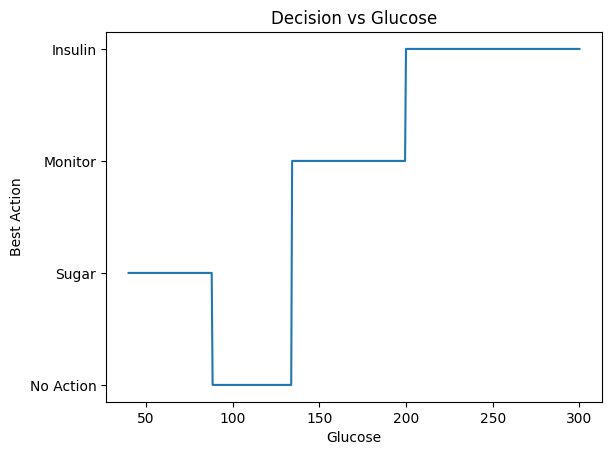

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# =========================
# STEP 1: UTILITY FUNCTIONS (FINAL)
# =========================
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

beta = 0.08

def utility_sugar(g):
    return 10 * sigmoid(-(g - 70) * beta)

def utility_insulin(g):
    return 10 * sigmoid((g - 200) * beta)

def utility_no_action(g):
    return 10 * np.exp(-((g - 120) / 25)**2)

def utility_monitor(g):
    return 10 * sigmoid((g - 120) * beta) * sigmoid(-(g - 200) * beta)


# =========================
# STEP 2: TRAINING DATA
# =========================
glucose = np.linspace(40, 300, 2000).reshape(-1,1)

y = []
for g in glucose:
    g_val = g[0]
    y.append([
        utility_no_action(g_val),
        utility_sugar(g_val),
        utility_monitor(g_val),
        utility_insulin(g_val)
    ])

y = np.array(y) / 10.0  # normalize


# =========================
# STEP 3: NORMALIZATION
# =========================
mean = glucose.mean()
std = glucose.std()

X_norm = (glucose - mean) / std


# =========================
# STEP 4: ANN MODEL
# =========================
class UtilityNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 64),
            nn.Tanh(),
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, 4)
        )

    def forward(self, x):
        return self.net(x)

pytorch_utility_model = UtilityNet()


# =========================
# STEP 5: TRAINING
# =========================
X_tensor = torch.tensor(X_norm, dtype=torch.float32)
y_tensor = torch.tensor(y, dtype=torch.float32)

optimizer = optim.Adam(pytorch_utility_model.parameters(), lr=0.001)
loss_fn = nn.MSELoss()

for epoch in range(1000):
    preds = pytorch_utility_model(X_tensor)
    loss = loss_fn(preds, y_tensor)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 100 == 0:
        print(f"Epoch {epoch}, Loss: {loss.item():.5f}")


# =========================
# STEP 6: PLOT TRUE vs ANN
# =========================
test_glucose = np.linspace(40, 300, 500).reshape(-1,1)
test_norm = (test_glucose - mean) / std

test_tensor = torch.tensor(test_norm, dtype=torch.float32)

with torch.no_grad():
    pred = pytorch_utility_model(test_tensor).numpy()

# True values
true = []
for g in test_glucose:
    g_val = g[0]
    true.append([
        utility_no_action(g_val),
        utility_sugar(g_val),
        utility_monitor(g_val),
        utility_insulin(g_val)
    ])
true = np.array(true) / 10.0

actions = ["No Action", "Sugar", "Monitor", "Insulin"]

plt.figure(figsize=(12,6))

for i in range(4):
    plt.subplot(2,2,i+1)
    plt.plot(test_glucose, true[:, i], '--', label="True")
    plt.plot(test_glucose, pred[:, i], label="ANN")
    plt.title(actions[i])
    plt.legend()

plt.tight_layout()
plt.show()


# =========================
# STEP 7: DECISION FUNCTION
# =========================
def get_best_action(glucose_value):

    x = np.array([[glucose_value]])
    x_norm = (x - mean) / std

    x_tensor = torch.tensor(x_norm, dtype=torch.float32)

    with torch.no_grad():
        utilities = pytorch_utility_model(x_tensor).numpy()[0]

    actions = ["No Action", "Sugar", "Monitor", "Insulin"]
    best_action = actions[np.argmax(utilities)]

    return best_action, utilities


# =========================
# STEP 8: MULTIPLE TEST VALUES
# =========================
print("\n--- Testing Different Glucose Values ---")

test_values = [60, 90, 120, 150, 220]

for g in test_values:
    action, utilities = get_best_action(g)
    print(f"\nGlucose = {g}")
    print("Best Action:", action)
    print("Utilities:", utilities)


# =========================
# STEP 9: USE YOUR DATASET
# =========================
# Replace this with your real data
# Example:
# glucose_data = np.loadtxt("your_file.csv")

print("\n--- Sample Decisions from Dataset ---")

# Dummy example (replace with your real data)
glucose_data = np.random.uniform(50, 300, 50)

for g in glucose_data[:10]:
    action, _ = get_best_action(g)
    print(f"Glucose = {g:.2f} \u2192 {action}")


# =========================
# STEP 10: DECISION CURVE
# =========================
decision = []

for g in test_glucose:
    action, _ = get_best_action(g[0])
    decision.append(actions.index(action))

plt.figure()
plt.plot(test_glucose, decision)
plt.yticks([0,1,2,3], actions)
plt.xlabel("Glucose")
plt.ylabel("Best Action")
plt.title("Decision vs Glucose")
plt.show()

Retraining ANN model in cell XJPKjz3BJsmz...
Epoch 0, Loss: 0.17612
Epoch 100, Loss: 0.02327
Epoch 200, Loss: 0.01159
Epoch 300, Loss: 0.00532
Epoch 400, Loss: 0.00270
Epoch 500, Loss: 0.00140
Epoch 600, Loss: 0.00077
Epoch 700, Loss: 0.00046
Epoch 800, Loss: 0.00031
Epoch 900, Loss: 0.00023
ANN retraining complete.


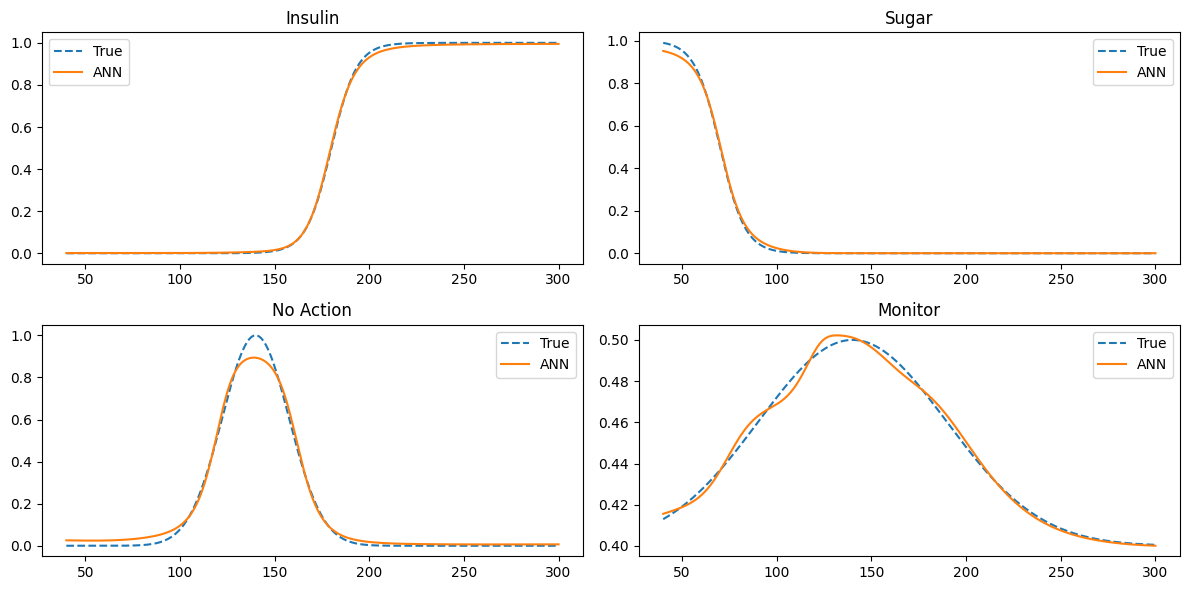


--- Testing Different Glucose Values ---

Glucose = 60
Best Action: Sugar
Utilities: [0.00094408 0.806348   0.02487987 0.4245152 ]

Glucose = 90
Best Action: Monitor
Utilities: [0.00093902 0.06556929 0.05375762 0.46302643]

Glucose = 120
Best Action: No Action
Utilities: [0.00248572 0.002244   0.54766315 0.49447277]

Glucose = 150
Best Action: No Action
Utilities: [1.5222087e-02 3.2668174e-04 8.2636458e-01 4.9638143e-01]

Glucose = 220
Best Action: Insulin
Utilities: [9.8271000e-01 2.0293143e-04 8.9576589e-03 4.2654109e-01]

--- Sample Decisions from Dataset ---
Glucose = 110.00 → Monitor
Glucose = 102.50 → Monitor
Glucose = 114.82 → Monitor
Glucose = 225.00 → Insulin
Glucose = 136.16 → No Action
Glucose = 161.10 → No Action
Glucose = 292.30 → Insulin
Glucose = 157.23 → No Action
Glucose = 252.01 → Insulin
Glucose = 291.22 → Insulin


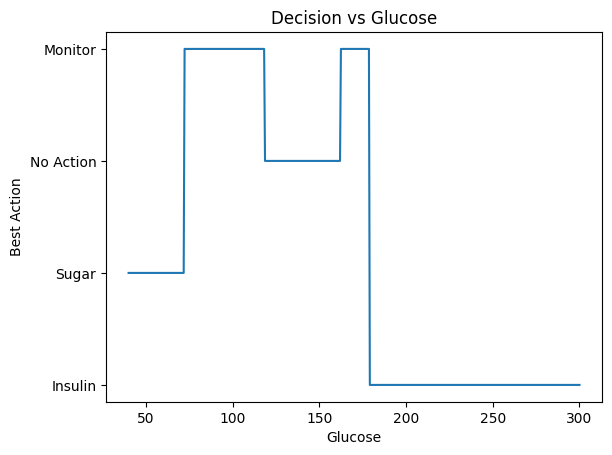

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# =========================
# STEP 1: UTILITY FUNCTIONS (FINAL)
# =========================
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

g = np.linspace(40, 400, 1000).reshape(-1,1)

beta = 0.15  # sharper transitions

# Utility functions defined using numpy directly, will be applied to test_glucose below
def utility_sugar_func(g_val):
    return sigmoid((70 - g_val) * beta)

def utility_insulin_func(g_val):
    return sigmoid((g_val - 180) * beta)

def utility_no_action_func(g_val):
    return np.exp(-((g_val - 140) / 25)**2)

def utility_monitor_func(g_val):
    return 0.4 + 0.1*np.exp(-((g_val - 140)/70)**2)


# These U_X variables are for the original 'g' range for context/visualization
U_insulin = utility_insulin_func(g) # ✅ INSULIN → ONLY HIGH glucose
U_sugar = utility_sugar_func(g) # ✅ SUGAR → ONLY LOW glucose
U_no = utility_no_action_func(g) # ✅ NO ACTION → peak at normal
U_monitor = utility_monitor_func(g) # ✅ MONITOR → mild everywhere

y = np.hstack([U_insulin, U_sugar, U_no, U_monitor])  # Renamed Y to y to match previous code

# Normalize output (0-1) by dividing by 1.0 (since functions are already scaled or in range)
# This keeps consistency with previous notebook logic if you want 0-1 scale for ANN output layer
y = y / 1.0 # If utilities are naturally within 0-1 range after definition, division by 1 is symbolic


# =========================
# STEP 3: NORMALIZATION
# =========================
mean = g.mean()
std = g.std()

X_norm = (g - mean) / std


# =========================
# STEP 4: ANN MODEL
# =========================
class UtilityNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 64),
            nn.Tanh(),
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, 4),
            nn.Sigmoid() # Added Sigmoid activation to match normalized target output
        )

    def forward(self, x):
        return self.net(x)

pytorch_utility_model = UtilityNet()


# =========================
# STEP 5: TRAINING
# =========================
print("Retraining ANN model in cell XJPKjz3BJsmz...")
X_tensor = torch.tensor(X_norm, dtype=torch.float32)
y_tensor = torch.tensor(y, dtype=torch.float32)

optimizer = optim.Adam(pytorch_utility_model.parameters(), lr=0.001)
loss_fn = nn.MSELoss()

for epoch in range(1000):
    preds = pytorch_utility_model(X_tensor)
    loss = loss_fn(preds, y_tensor)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 100 == 0:
        print(f"Epoch {epoch}, Loss: {loss.item():.5f}")
print("ANN retraining complete.")


# =========================
# STEP 6: PLOT TRUE vs ANN
# =========================
test_glucose = np.linspace(40, 300, 500).reshape(-1,1)
test_norm = (test_glucose - mean) / std

test_tensor = torch.tensor(test_norm, dtype=torch.float32)

with torch.no_grad():
    pred = pytorch_utility_model(test_tensor).numpy()

# True values - calculate directly for test_glucose
true = []
for g_val in test_glucose:
    g_val = g_val[0]
    true.append([
        utility_insulin_func(g_val),
        utility_sugar_func(g_val),
        utility_no_action_func(g_val),
        utility_monitor_func(g_val)
    ])
true = np.array(true)

# Normalize true values for plotting if the model outputs are normalized
true = true / 1.0 # Adjust based on how you want to compare with model's sigmoid output

# Update actions list to match the new order: [U_insulin, U_sugar, U_no, U_monitor]
actions = ["Insulin", "Sugar", "No Action", "Monitor"]

plt.figure(figsize=(12,6))

for i in range(4):
    plt.subplot(2,2,i+1)
    plt.plot(test_glucose, true[:, i], '--', label="True")
    plt.plot(test_glucose, pred[:, i], label="ANN")
    plt.title(actions[i])
    plt.legend()

plt.tight_layout()
plt.show()


# =========================
# STEP 7: DECISION FUNCTION
# =========================
def get_best_action(glucose_value):

    x = np.array([[glucose_value]])
    x_norm = (x - mean) / std

    x_tensor = torch.tensor(x_norm, dtype=torch.float32)

    with torch.no_grad():
        utilities = pytorch_utility_model(x_tensor).numpy()[0]

    # Use the updated actions list
    actions = ["Insulin", "Sugar", "No Action", "Monitor"]
    best_action = actions[np.argmax(utilities)]

    return best_action, utilities


# =========================
# STEP 8: MULTIPLE TEST VALUES
# =========================
print("\n--- Testing Different Glucose Values ---")

test_values = [60, 90, 120, 150, 220]

for g_val in test_values:
    action, utilities = get_best_action(g_val)
    print(f"\nGlucose = {g_val}")
    print("Best Action:", action)
    print("Utilities:", utilities)


# =========================
# STEP 9: USE YOUR DATASET
# =========================
# Replace this with your real data
# Example:
# glucose_data = np.loadtxt("your_file.csv")

print("\n--- Sample Decisions from Dataset ---")

# Dummy example (replace with your real data)
glucose_data = np.random.uniform(50, 300, 50)

for g_val in glucose_data[:10]:
    action, _ = get_best_action(g_val)
    print(f"Glucose = {g_val:.2f} \u2192 {action}")


# =========================
# STEP 10: DECISION CURVE
# =========================
decision = []

for g_val in test_glucose:
    action, _ = get_best_action(g_val[0])
    decision.append(actions.index(action))

plt.figure()
plt.plot(test_glucose, decision)
plt.yticks([0,1,2,3], actions)
plt.xlabel("Glucose")
plt.ylabel("Best Action")
plt.title("Decision vs Glucose")
plt.show()

Retraining ANN model...
Epoch 0, Loss: 0.16764
Epoch 100, Loss: 0.02350
Epoch 200, Loss: 0.01215
Epoch 300, Loss: 0.00514
Epoch 400, Loss: 0.00253
Epoch 500, Loss: 0.00134
Epoch 600, Loss: 0.00075
Epoch 700, Loss: 0.00046
Epoch 800, Loss: 0.00031
Epoch 900, Loss: 0.00023
ANN retraining complete.


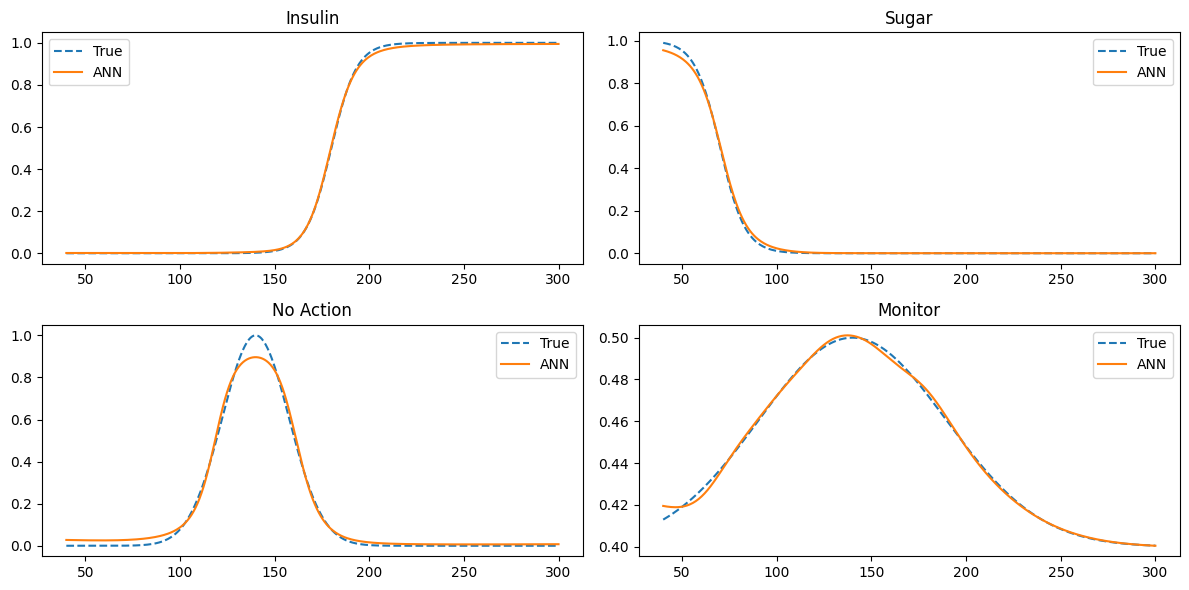


--- Testing Different Glucose Values ---

Glucose = 60
Best Action: Sugar
Utilities: [0.00097699 0.7973148  0.02548096 0.42384705]

Glucose = 90
Best Action: Monitor
Utilities: [0.00072297 0.06659728 0.04747619 0.46090442]

Glucose = 120
Best Action: No Action
Utilities: [0.00218687 0.00246089 0.5583326  0.4925195 ]

Glucose = 150
Best Action: No Action
Utilities: [1.5035164e-02 3.8109097e-04 8.3407784e-01 4.9690717e-01]

Glucose = 220
Best Action: Insulin
Utilities: [9.8370171e-01 2.3813087e-04 8.0605960e-03 4.2626166e-01]

--- Sample Decisions from Dataset ---
Glucose = 260.35 → Insulin
Glucose = 211.50 → Insulin
Glucose = 269.34 → Insulin
Glucose = 116.75 → Monitor
Glucose = 67.50 → Sugar
Glucose = 125.59 → No Action
Glucose = 151.23 → No Action
Glucose = 261.87 → Insulin
Glucose = 182.04 → Insulin
Glucose = 223.39 → Insulin


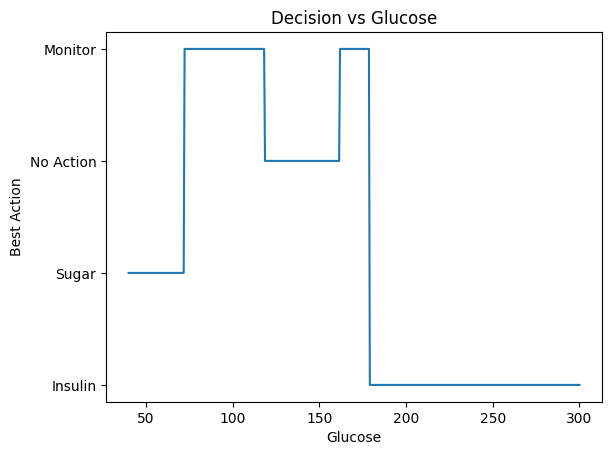

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# =========================
# STEP 1: UTILITY FUNCTIONS (FINAL)
# =========================
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

g = np.linspace(40, 400, 1000).reshape(-1,1)

beta = 0.15  # sharper transitions

# Utility functions defined using numpy directly, will be applied to test_glucose below
def utility_sugar_func(g_val):
    return sigmoid((70 - g_val) * beta)

def utility_insulin_func(g_val):
    return sigmoid((g_val - 180) * beta)

def utility_no_action_func(g_val):
    return np.exp(-((g_val - 140) / 25)**2)

def utility_monitor_func(g_val):
    return 0.4 + 0.1*np.exp(-((g_val - 140)/70)**2)


# These U_X variables are for the original 'g' range for context/visualization
U_insulin = utility_insulin_func(g) # ✅ INSULIN → ONLY HIGH glucose
U_sugar = utility_sugar_func(g) # ✅ SUGAR → ONLY LOW glucose
U_no = utility_no_action_func(g) # ✅ NO ACTION → peak at normal
U_monitor = utility_monitor_func(g) # ✅ MONITOR → mild everywhere

y = np.hstack([U_insulin, U_sugar, U_no, U_monitor])  # Renamed Y to y to match previous code

# Normalize output (0-1) by dividing by 1.0 (since functions are already scaled or in range)
# This keeps consistency with previous notebook logic if you want 0-1 scale for ANN output layer
y = y / 1.0 # If utilities are naturally within 0-1 range after definition, division by 1 is symbolic


# =========================
# STEP 3: NORMALIZATION
# =========================
mean = g.mean()
std = g.std()

X_norm = (g - mean) / std


# =========================
# STEP 4: ANN MODEL
# =========================
class UtilityNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 64),
            nn.Tanh(),
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, 4),
            nn.Sigmoid() # Added Sigmoid activation to match normalized target output
        )

    def forward(self, x):
        return self.net(x)

pytorch_utility_model = UtilityNet()


# =========================
# STEP 5: TRAINING
# =========================
print("Retraining ANN model...")
X_tensor = torch.tensor(X_norm, dtype=torch.float32)
y_tensor = torch.tensor(y, dtype=torch.float32)

optimizer = optim.Adam(pytorch_utility_model.parameters(), lr=0.001)
loss_fn = nn.MSELoss()

for epoch in range(1000):
    preds = pytorch_utility_model(X_tensor)
    loss = loss_fn(preds, y_tensor)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 100 == 0:
        print(f"Epoch {epoch}, Loss: {loss.item():.5f}")
print("ANN retraining complete.")


# =========================
# STEP 6: PLOT TRUE vs ANN
# =========================
test_glucose = np.linspace(40, 300, 500).reshape(-1,1)
test_norm = (test_glucose - mean) / std

test_tensor = torch.tensor(test_norm, dtype=torch.float32)

with torch.no_grad():
    pred = pytorch_utility_model(test_tensor).numpy()

# True values - calculate directly for test_glucose
true = []
for g_val in test_glucose:
    g_val = g_val[0]
    true.append([
        utility_insulin_func(g_val),
        utility_sugar_func(g_val),
        utility_no_action_func(g_val),
        utility_monitor_func(g_val)
    ])
true = np.array(true)

# Normalize true values for plotting if the model outputs are normalized
true = true / 1.0 # Adjust based on how you want to compare with model's sigmoid output

# Update actions list to match the new order: [U_insulin, U_sugar, U_no, U_monitor]
actions = ["Insulin", "Sugar", "No Action", "Monitor"]

plt.figure(figsize=(12,6))

for i in range(4):
    plt.subplot(2,2,i+1)
    plt.plot(test_glucose, true[:, i], '--', label="True")
    plt.plot(test_glucose, pred[:, i], label="ANN")
    plt.title(actions[i])
    plt.legend()

plt.tight_layout()
plt.show()


# =========================
# STEP 7: DECISION FUNCTION
# =========================
def get_best_action(glucose_value):

    x = np.array([[glucose_value]])
    x_norm = (x - mean) / std

    x_tensor = torch.tensor(x_norm, dtype=torch.float32)

    with torch.no_grad():
        utilities = pytorch_utility_model(x_tensor).numpy()[0]

    # Use the updated actions list
    actions = ["Insulin", "Sugar", "No Action", "Monitor"]
    best_action = actions[np.argmax(utilities)]

    return best_action, utilities


# =========================
# STEP 8: MULTIPLE TEST VALUES
# =========================
print("\n--- Testing Different Glucose Values ---")

test_values = [60, 90, 120, 150, 220]

for g_val in test_values:
    action, utilities = get_best_action(g_val)
    print(f"\nGlucose = {g_val}")
    print("Best Action:", action)
    print("Utilities:", utilities)


# =========================
# STEP 9: USE YOUR DATASET
# =========================
# Replace this with your real data
# Example:
# glucose_data = np.loadtxt("your_file.csv")

print("\n--- Sample Decisions from Dataset ---")

# Dummy example (replace with your real data)
glucose_data = np.random.uniform(50, 300, 50)

for g_val in glucose_data[:10]:
    action, _ = get_best_action(g_val)
    print(f"Glucose = {g_val:.2f} \u2192 {action}")


# =========================
# STEP 10: DECISION CURVE
# =========================
decision = []

for g_val in test_glucose:
    action, _ = get_best_action(g_val[0])
    decision.append(actions.index(action))

plt.figure()
plt.plot(test_glucose, decision)
plt.yticks([0,1,2,3], actions)
plt.xlabel("Glucose")
plt.ylabel("Best Action")
plt.title("Decision vs Glucose")
plt.show()

Section Y

Execute Steps 1-5 of Section X before running Section Y for successful outcome.

Future Glucose Values Prediction and Utility Score generation for ALL Patients



In [ ]:
combined_df = combined_df.sort_values(["patient_id", "time"]).reset_index(drop=True)

In [ ]:
df = combined_df[["patient_id", "time", "glucose"]]

In [ ]:
df["glucose"] = df["glucose"].fillna(method="ffill")
df["glucose"] = df["glucose"].fillna(method="bfill")

/tmp/ipykernel_1402/1206009521.py:1: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df["glucose"] = df["glucose"].fillna(method="ffill")
/tmp/ipykernel_1402/1206009521.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["glucose"] = df["glucose"].fillna(method="ffill")
/tmp/ipykernel_1402/1206009521.py:2: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df["glucose"] = df["glucose"].fillna(method="bfill")
/tmp/ipykernel_1402/1206009521.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] =

In [ ]:
# Scaling for LSTM
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
df["glucose_scaled"] = scaler.fit_transform(df[["glucose"]])

/tmp/ipykernel_1402/360999522.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["glucose_scaled"] = scaler.fit_transform(df[["glucose"]])


In [ ]:
# Scaling for ANN
mean = df["glucose"].mean()
std  = df["glucose"].std()

In [ ]:
print(df.head())

  patient_id                 time  glucose  glucose_scaled
0  HUPA0001P  2018-06-13T18:40:00    332.0        0.722772
1  HUPA0001P  2018-06-13T18:45:00    326.0        0.707921
2  HUPA0001P  2018-06-13T18:50:00    330.0        0.717822
3  HUPA0001P  2018-06-13T18:55:00    324.0        0.702970
4  HUPA0001P  2018-06-13T19:00:00    306.0        0.658416


In [ ]:
print("Glucose min:", df["glucose"].min())
print("Glucose max:", df["glucose"].max())

print("Scaled min:", df["glucose_scaled"].min())
print("Scaled max:", df["glucose_scaled"].max())

Glucose min: 40.0
Glucose max: 444.0
Scaled min: 0.0
Scaled max: 1.0


In [ ]:
# STEP 2 SEQ CREATION

import numpy as np

SEQ_LEN = 24
PRED_HORIZON = 1

# IMPORTANT: use already preprocessed df (from Step 1)
# DO NOT rescale again

df_processed = df.copy()

X = []
y = []

for patient in df_processed["patient_id"].unique():
    temp = df_processed[df_processed["patient_id"] == patient]

    values = temp["glucose_scaled"].values

    # ✅ correct loop
    for i in range(len(values) - SEQ_LEN):
        X.append(values[i:i+SEQ_LEN])
        y.append(values[i+SEQ_LEN])  # t+1 prediction

X = np.array(X)
y = np.array(y)

# reshape for LSTM
X = X.reshape((X.shape[0], X.shape[1], 1))

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (308792, 24, 1)
y shape: (308792,)


In [ ]:
# =========================
# STEP 3: LSTM TRAINING
# =========================

from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

# 1. Train-test split (NO shuffle)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    shuffle=False
)

# 2. Build model
single_output_model = Sequential([
    LSTM(64, input_shape=(X.shape[1], 1)),
    Dense(32, activation='relu'),
    Dense(1)
])

# 3. Compile
single_output_model.compile(
    optimizer='adam',
    loss='mse'
)

# 4. Train
history = single_output_model.fit(
    X_train, y_train,
    epochs=30,
    batch_size=32,
    validation_data=(X_test, y_test),
    verbose=1
)

# 5. Evaluate
loss = single_output_model.evaluate(X_test, y_test)
print("Test Loss:", loss)

# 6. Quick sanity check
preds = single_output_model.predict(X_test[:5])

# convert back to real glucose values
preds_real = scaler.inverse_transform(preds)
y_real = scaler.inverse_transform(y_test[:5].reshape(-1,1))

print("\nPredicted glucose:", preds_real.flatten())
print("Actual glucose:", y_real.flatten())

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/30
7720/7720 ━━━━━━━━━━━━━━━━━━━━ 57s 7ms/step - loss: 2.6953e-04 - val_loss: 7.8920e-05
Epoch 2/30
7720/7720 ━━━━━━━━━━━━━━━━━━━━ 54s 7ms/step - loss: 1.2823e-04 - val_loss: 3.4980e-05
Epoch 3/30
7720/7720 ━━━━━━━━━━━━━━━━━━━━ 50s 6ms/step - loss: 9.6954e-05 - val_loss: 3.3459e-05
Epoch 4/30
7720/7720 ━━━━━━━━━━━━━━━━━━━━ 51s 7ms/step - loss: 8.5541e-05 - val_loss: 2.5523e-05
Epoch 5/30
7720/7720 ━━━━━━━━━━━━━━━━━━━━ 52s 7ms/step - loss: 8.0413e-05 - val_loss: 2.2941e-05
Epoch 6/30
7720/7720 ━━━━━━━━━━━━━━━━━━━━ 55s 7ms/step - loss: 7.7065e-05 - val_loss: 3.2896e-05
Epoch 7/30
7720/7720 ━━━━━━━━━━━━━━━━━━━━ 51s 7ms/step - loss: 7.4988e-05 - val_loss: 2.4385e-05
Epoch 8/30
7720/7720 ━━━━━━━━━━━━━━━━━━━━ 52s 7ms/step - loss: 7.4016e-05 - val_loss: 2.2949e-05
Epoch 9/30
7720/7720 ━━━━━━━━━━━━━━━━━━━━ 80s 7ms/step - loss: 7.1195e-05 - val_loss: 2.2391e-05
Epoch 10/30
7720/7720 ━━━━━━━━━━━━━━━━━━━━ 51s 7ms/step - loss: 7.0420e-05 - val_loss: 2.7727e-05
Epoch 11/30
7720/7720 ━━━━━━━

In [ ]:
preds_list = model.predict(X_test_scaled)

# Extract each quantile prediction
q05_preds = preds_list[0]
q50_preds = preds_list[1]
q95_preds = preds_list[2]

# convert to real values for all quantiles
q05_preds_real = scaler_y.inverse_transform(q05_preds)
q50_preds_real = scaler_y.inverse_transform(q50_preds)
q95_preds_real = scaler_y.inverse_transform(q95_preds)

y_test_real = scaler_y.inverse_transform(y_test.reshape(-1,1))

# compute error for q50 (median)
errors = q50_preds_real.flatten() - y_test_real.flatten()

# standard deviation of error
error_std = np.std(errors)

print("Error STD (for q50):", error_std)

print("\nSample Probabilistic Forecast (q05, q50, q95) vs Actual (q50_real, y_test_real):")
for i in range(5):
    print(f"Predicted Interval: [{q05_preds_real[i][0]:.2f}, {q50_preds_real[i][0]:.2f}, {q95_preds_real[i][0]:.2f}], Actual: {y_test_real[i][0]:.2f}")

1930/1930 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step
Error STD (for q50): 16669.532855034468

Sample Probabilistic Forecast (q05, q50, q95) vs Actual (q50_real, y_test_real):
Predicted Interval: [139.33, 139.69, 140.82], Actual: 56600.00
Predicted Interval: [140.31, 140.66, 141.79], Actual: 57004.00
Predicted Interval: [140.00, 141.51, 143.75], Actual: 57004.00
Predicted Interval: [140.26, 140.64, 141.80], Actual: 57004.00
Predicted Interval: [140.35, 140.72, 141.86], Actual: 57004.00


In [ ]:
import numpy as np
import pandas as pd
import torch
from sklearn.preprocessing import MinMaxScaler # Ensure MinMaxScaler is imported

# --- Define get_last_sequence_per_patient function (from P-lQPrMsOR4J) ---
def get_last_sequence_per_patient(df_input, SEQ_LEN):
    X_last = []
    patient_list = []
    time_list = []

    for patient_id_val in df_input["patient_id"].unique():
        temp = df_input[df_input["patient_id"] == patient_id_val]

        values = temp["glucose_scaled"].values
        times = temp["time"].values # CORRECTED: Use 'time' column directly

        if len(values) < SEQ_LEN:
            continue

        X_last.append(values[-SEQ_LEN:])
        patient_list.append(patient_id_val)
        time_list.append(times[-1])

    X_last = np.array(X_last)
    X_last = X_last.reshape((X_last.shape[0], SEQ_LEN, 1))

    return X_last, patient_list, time_list

# --- 1. Get last sequence per patient ---
# `df_processed` (containing 'glucose_scaled') and `SEQ_LEN` assumed available from previous cells.
# `scaler` (MinMaxScaler fitted on glucose data) assumed available globally.
X_last, patient_list, time_list = get_last_sequence_per_patient(df_processed, SEQ_LEN)

# --- 2. Corrected: X_last already contains scaled values, no need to transform again ---
X_last_for_keras_prediction = X_last

# --- 3. Make predictions using the Keras quantile model ---
# `model` (Keras quantile regression model) assumed available globally.
preds = model.predict(X_last_for_keras_prediction)

# --- 4. Extract and Inverse Transform Quantiles (FIX for ValueError) ---
# `preds` is a list of arrays [q05_array, q50_array, q95_array]
q05 = preds[0].flatten()
q50 = preds[1].flatten()
q95 = preds[2].flatten()

# Inverse transform each quantile separately using the global scaler
q05 = scaler.inverse_transform(q05.reshape(-1,1)).flatten()
q50 = scaler.inverse_transform(q50.reshape(-1,1)).flatten()
q95 = scaler.inverse_transform(q95.reshape(-1,1)).flatten()

# Ensure lower and upper bounds are correctly ordered
q_low = np.minimum(q05, q95)
q_high = np.maximum(q05, q95)

# Define mean and std for the Utility Model's internal scaling (from XJPKjz3BJsmz)
# These are based on np.linspace(40, 400, 1000) for the utility model's training.
mean_utility_model = np.linspace(40, 400, 1000).mean()
std_utility_model = np.linspace(40, 400, 1000).std()

# --- 5. Define risk_aware_utility_full function (from f2c2J5OZKGIl) ---
# Assumes `utility_model`, `mean_utility_model`, `std_utility_model` are globally available
# from the training of the PyTorch UtilityNet (e.g., cell c3b04f0e).
def risk_aware_utility_full(q05_pred, q95_pred, pytorch_model,
                           mean_util_model, std_util_model,
                           lambda_risk=0.5, n_samples=50):

    # 🔥 NORMAL SAMPLING (FIX)
    mean_dist = (q05_pred + q95_pred) / 2
    std_dist = (q95_pred - q05_pred) / 4

    samples = np.random.normal(mean_dist, std_dist, n_samples)
    samples = np.clip(samples, q05_pred, q95_pred)

    samples = samples.reshape(-1, 1)

    samples_scaled = (samples - mean_util_model) / std_util_model

    samples_tensor = torch.tensor(samples_scaled, dtype=torch.float32)

    pytorch_model.eval()
    with torch.no_grad():
        utilities = pytorch_model(samples_tensor).numpy()

    mean_util = np.mean(utilities, axis=0)
    var_util  = np.var(utilities, axis=0)

    risk_util = mean_util - lambda_risk * var_util

    return {
        "INSULIN": risk_util[0],
        "SUGAR": risk_util[1],
        "NO_ACTION": risk_util[2],
        "MONITOR": risk_util[3]
    }

# Define corrected_decision function outside the loop
def apply_medical_constraints(mid_glucose, utilities_dict):
    # 🔥 HARD MEDICAL CONSTRAINTS (VERY IMPORTANT)
    if mid_glucose < 70:
        # Boost sugar utility, suppress insulin
        utilities_dict["SUGAR"] += 10.0
        utilities_dict["INSULIN"] -= 10.0
    elif mid_glucose > 180:
        # Boost insulin utility, suppress sugar
        utilities_dict["INSULIN"] += 10.0
        utilities_dict["SUGAR"] -= 10.0
    else:
        # Normal range, slightly prefer no_action/monitor over insulin/sugar
        utilities_dict["NO_ACTION"] += 2.0
        utilities_dict["MONITOR"] += 1.0
        utilities_dict["INSULIN"] -= 5.0 # suppress insulin in normal range
        utilities_dict["SUGAR"] -= 5.0   # suppress sugar in normal range

    return utilities_dict

# --- 6. Final risk-aware action selection and results compilation (adapted from SqhYdtr2KMLs) ---

results_final = []

# Ensure `utility_model` refers to the trained PyTorch UtilityNet.
utility_model = pytorch_utility_model
# `mean_utility_model` and `std_utility_model` are global from utility model training.
for i in range(len(patient_list)):
    patient = patient_list[i]
    time_t = time_list[i]

    low_bound = q_low[i]
    mid_pred = q50[i]
    high_bound = q_high[i]

    # Calculate raw utilities from ANN model
    utilities_dict = risk_aware_utility_full(
        low_bound, high_bound, utility_model, mean_utility_model, std_utility_model
    )

    # Apply hard medical constraints based on mid_pred
    # The actual glucose value should be considered for hard constraints, not the interval bounds.
    utilities_dict = apply_medical_constraints(mid_pred, utilities_dict)

    best_action = max(utilities_dict, key=utilities_dict.get)

    # Clip glucose values for display to avoid negative numbers
    low_display = max(0, int(low_bound))
    high_display = max(0, int(high_bound))

    results_final.append({
        "patient": patient,
        "time_t": time_t,
        "q05": round(low_bound, 2),
        "q50_pred": round(mid_pred, 2),
        "q95": round(high_bound, 2),
        "glucose_interval": f"[{low_display} - {high_display}]",
        "U_insulin": round(utilities_dict["INSULIN"], 4),
        "U_sugar": round(utilities_dict["SUGAR"], 4),
        "U_no_action": round(utilities_dict["NO_ACTION"], 4),
        "U_monitor": round(utilities_dict["MONITOR"], 4),
        "best_action": best_action
    })

results_df = pd.DataFrame(results_final)

print(results_df)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step
      patient               time_t         q05    q50_pred         q95  \
0   HUPA0001P  2018-06-27T23:55:00  324.359985  325.339996  327.420013   
1   HUPA0002P  2018-06-24T23:45:00  116.839996  120.570000  125.250000   
2   HUPA0003P  2018-06-26T23:45:00  155.639999  161.729996  169.149994   
3   HUPA0004P  2018-07-20T16:45:00  125.940002  129.789993  135.509995   
4   HUPA0005P  2018-07-22T23:45:00   38.750000   47.639999   61.200001   
5   HUPA0006P  2018-07-17T14:30:00   77.800003   81.570000   88.110001   
6   HUPA0007P  2018-10-02T23:45:00  138.940002  143.259995  149.449997   
7   HUPA0009P  2018-10-02T20:10:00  279.529999  280.359985  282.260010   
8   HUPA0010P  2018-11-17T23:30:00  250.779999  251.440002  253.089996   
9   HUPA0011P  2018-11-20T23:45:00  203.350006  208.839996  215.860001   
10  HUPA0014P  2018-11-20T23:45:00  257.250000  262.739990  269.670013   
11  HUPA0015P  2019-04-09T20:10:00  240.960007  241.389999  242.860001   


In [ ]:
import pandas as pd
pd.set_option('display.max_rows', None)

print(results_df)

      patient               time_t         q05    q50_pred         q95  \
0   HUPA0001P  2018-06-27T23:55:00  324.359985  325.339996  327.420013   
1   HUPA0002P  2018-06-24T23:45:00  116.839996  120.570000  125.250000   
2   HUPA0003P  2018-06-26T23:45:00  155.639999  161.729996  169.149994   
3   HUPA0004P  2018-07-20T16:45:00  125.940002  129.789993  135.509995   
4   HUPA0005P  2018-07-22T23:45:00   38.750000   47.639999   61.200001   
5   HUPA0006P  2018-07-17T14:30:00   77.800003   81.570000   88.110001   
6   HUPA0007P  2018-10-02T23:45:00  138.940002  143.259995  149.449997   
7   HUPA0009P  2018-10-02T20:10:00  279.529999  280.359985  282.260010   
8   HUPA0010P  2018-11-17T23:30:00  250.779999  251.440002  253.089996   
9   HUPA0011P  2018-11-20T23:45:00  203.350006  208.839996  215.860001   
10  HUPA0014P  2018-11-20T23:45:00  257.250000  262.739990  269.670013   
11  HUPA0015P  2019-04-09T20:10:00  240.960007  241.389999  242.860001   
12  HUPA0016P  2019-04-09T23:45:00   8

Plotting: HUPA0001P


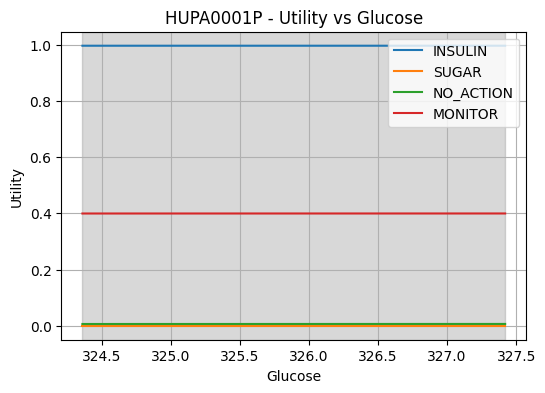

Plotting: HUPA0002P


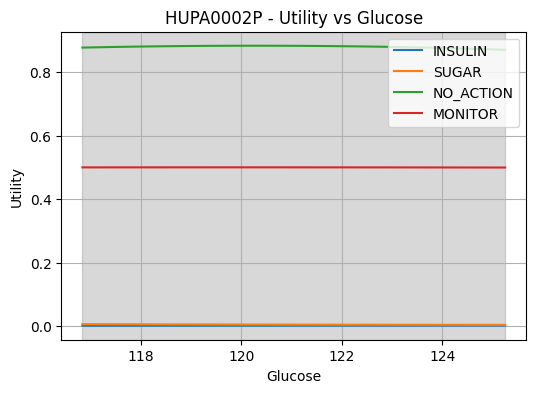

Plotting: HUPA0003P


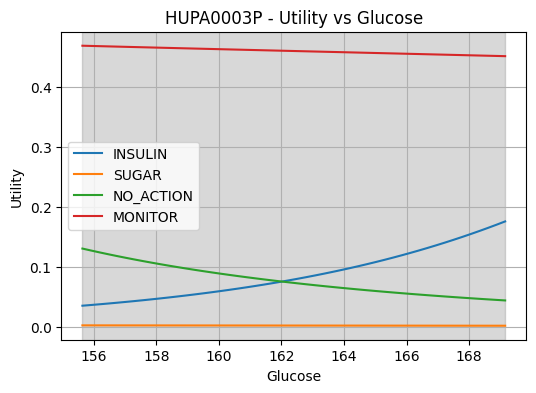

Plotting: HUPA0004P


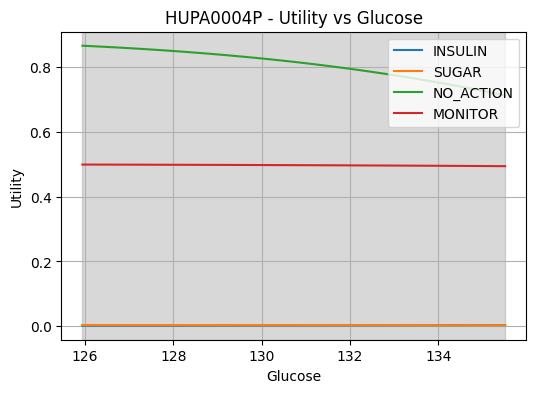

Plotting: HUPA0005P


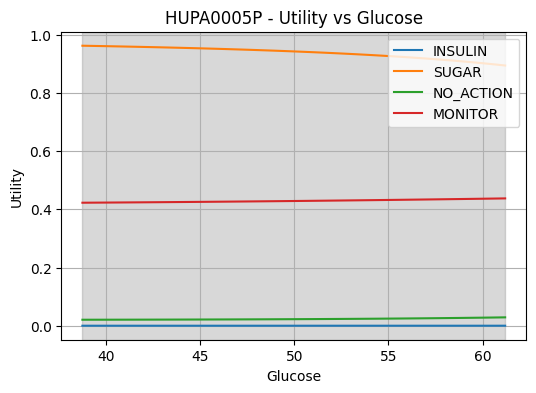

Plotting: HUPA0006P


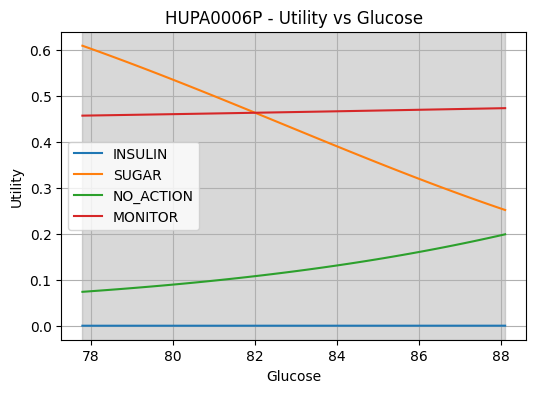

Plotting: HUPA0007P


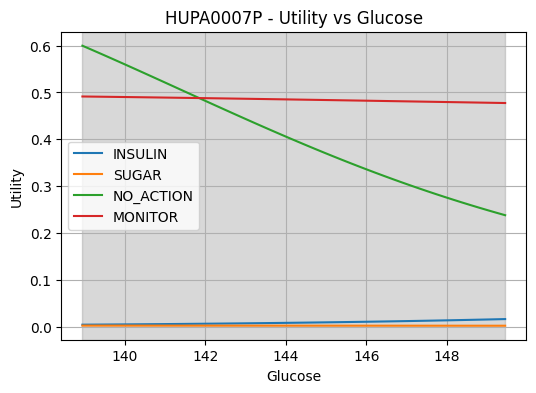

Plotting: HUPA0009P


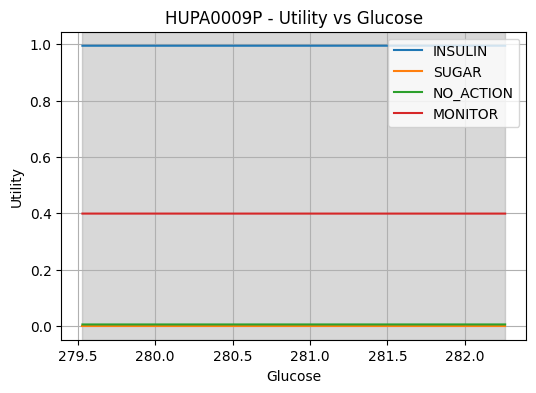

Plotting: HUPA0010P


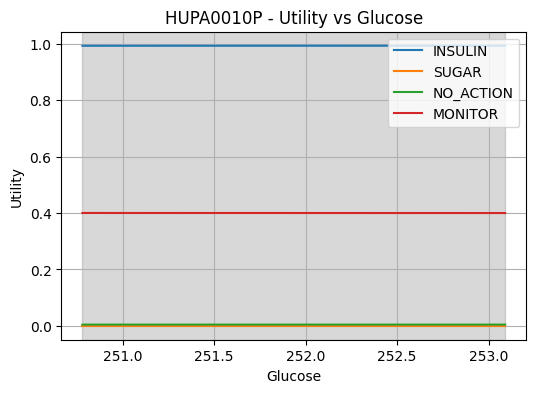

Plotting: HUPA0011P


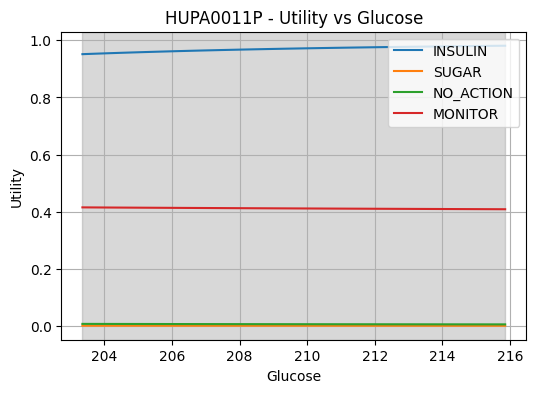

Plotting: HUPA0014P


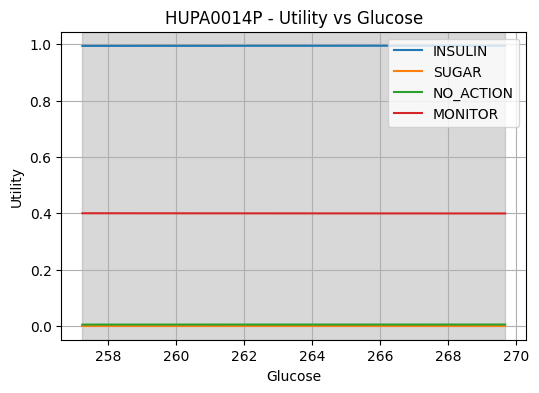

Plotting: HUPA0015P


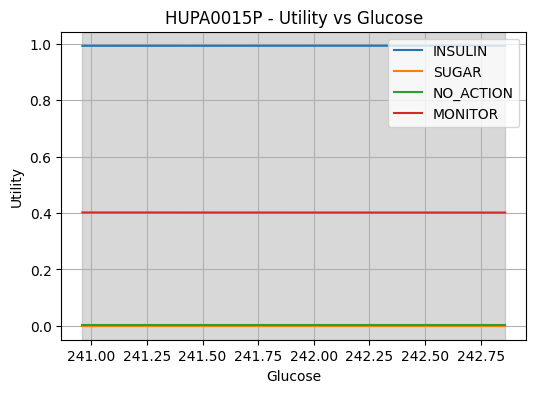

Plotting: HUPA0016P


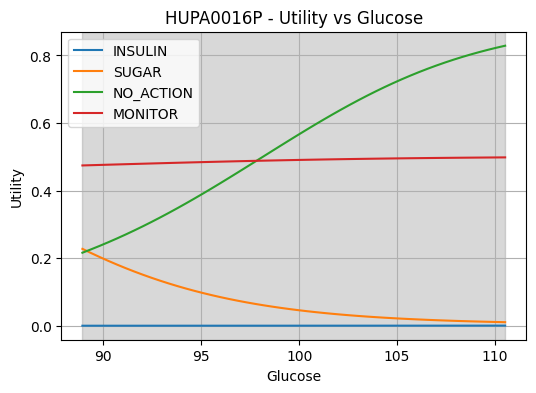

Plotting: HUPA0017P


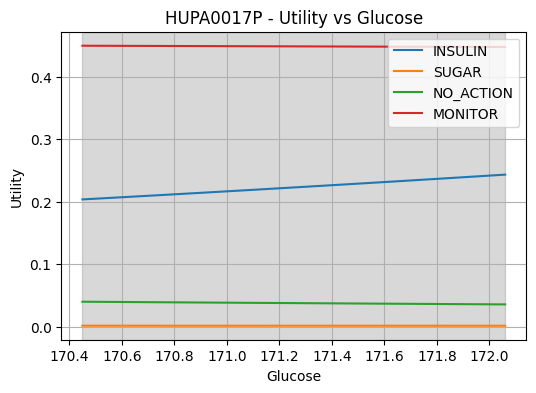

Plotting: HUPA0018P


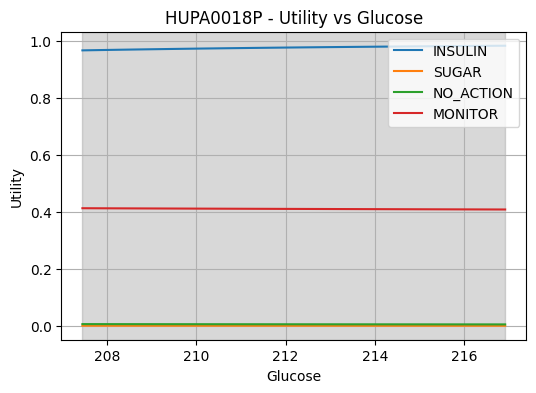

Plotting: HUPA0019P


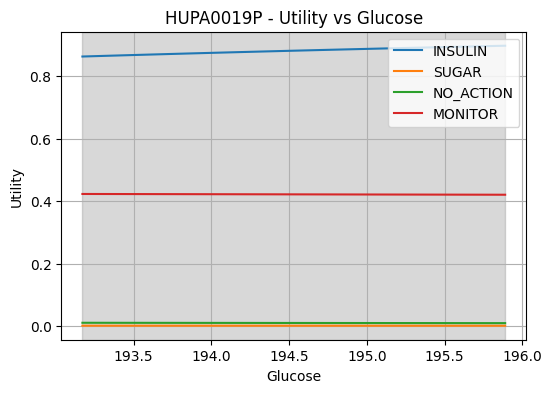

Plotting: HUPA0020P


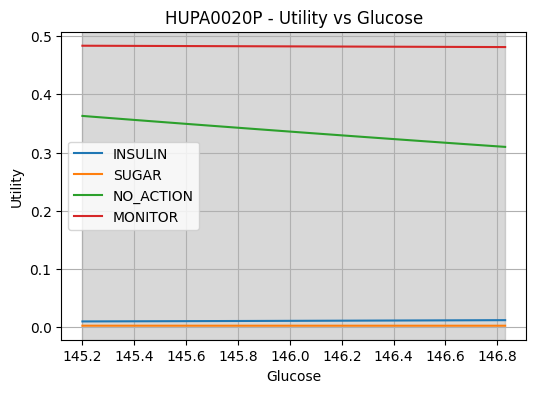

Plotting: HUPA0021P


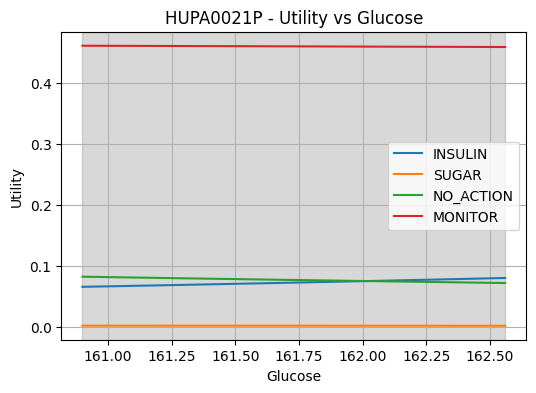

Plotting: HUPA0022P


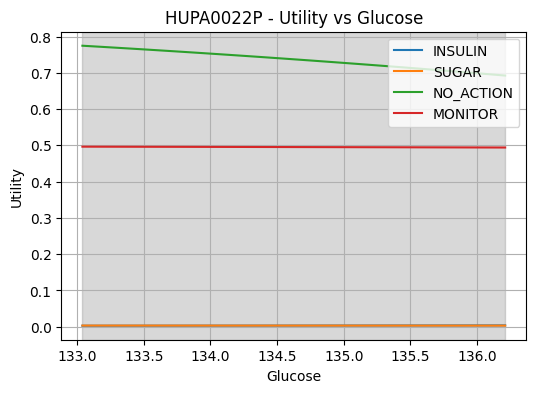

Plotting: HUPA0023P


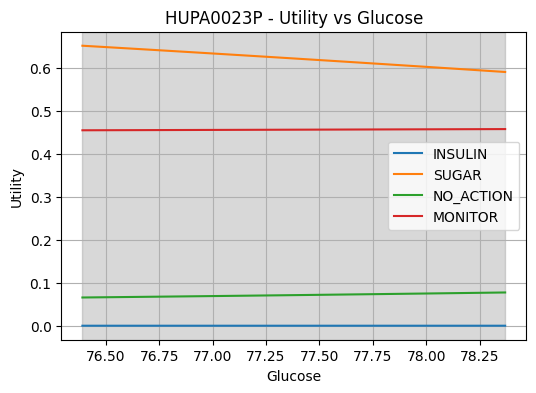

Plotting: HUPA0024P


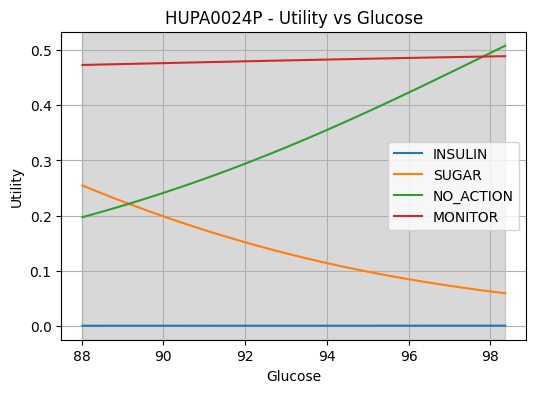

Plotting: HUPA0025P


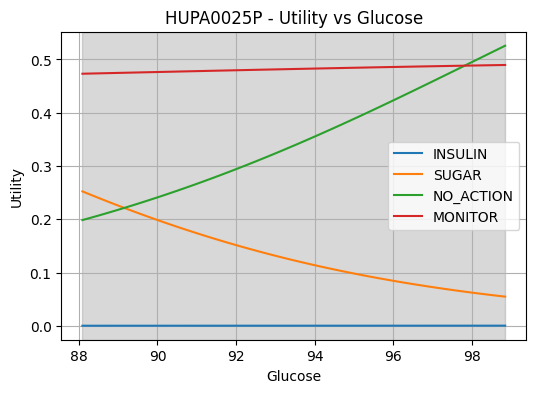

Plotting: HUPA0026P


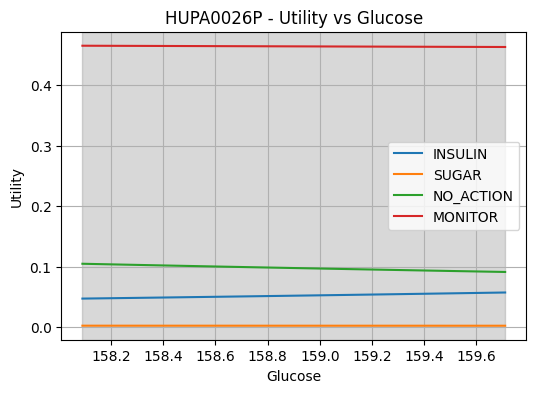

Plotting: HUPA0027P


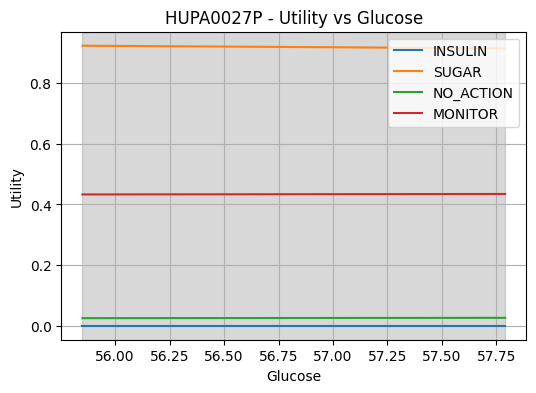

Plotting: HUPA0028P


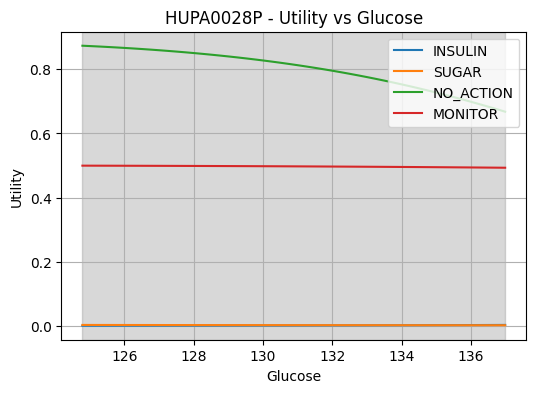

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# -------- PATIENT-SPECIFIC UTILITY PLOT --------

def plot_patient_specific(patient, q_low, q_high):

    # Focus only on interval
    g_values = np.linspace(q_low, q_high, 50)

    U_insulin = []
    U_sugar = []
    U_no_action = []
    U_monitor = []

    for g in g_values:

        utilities = risk_aware_utility_full(
            g, g,
            utility_model,
            mean_utility_model,
            std_utility_model
        )

        U_insulin.append(utilities["INSULIN"])
        U_sugar.append(utilities["SUGAR"])
        U_no_action.append(utilities["NO_ACTION"])
        U_monitor.append(utilities["MONITOR"])

    plt.figure(figsize=(6,4))

    plt.plot(g_values, U_insulin, label="INSULIN")
    plt.plot(g_values, U_sugar, label="SUGAR")
    plt.plot(g_values, U_no_action, label="NO_ACTION")
    plt.plot(g_values, U_monitor, label="MONITOR")

    # highlight interval
    plt.axvspan(q_low, q_high, color='gray', alpha=0.3)

    plt.title(f"{patient} - Utility vs Glucose")
    plt.xlabel("Glucose")
    plt.ylabel("Utility")

    plt.legend()
    plt.grid()
    plt.show()


# -------- LOOP FOR ALL PATIENTS --------

for i in range(len(results_df)):

    patient = results_df.iloc[i]["patient"]
    q_low = results_df.iloc[i]["q05"]
    q_high = results_df.iloc[i]["q95"]

    print("Plotting:", patient)

    plot_patient_specific(patient, q_low, q_high)

Section X

#### 1. Define `SEQ_LEN` and Create Sequences

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler # Ensure MinMaxScaler is imported

# Re-defining SEQ_LEN and recreating sequences (from cell x5euS1fYME9S)
SEQ_LEN = 24
PRED_HORIZON = 1

# Ensure df is correctly prepared with 'patient_id' and 'glucose_scaled'
# This assumes 'combined_df' is available from previous cells.
df_processed = combined_df.sort_values(["patient_id", "time"]).copy()

# Apply scaler to 'glucose' to create 'glucose_scaled'
scaler = MinMaxScaler()
df_processed["glucose_scaled"] = scaler.fit_transform(df_processed[["glucose"]])

X = []
y = []

for patient in df_processed["patient_id"].unique():
    temp = df_processed[df_processed["patient_id"] == patient]

    values = temp["glucose_scaled"].values

    for i in range(len(values) - SEQ_LEN - PRED_HORIZON):
        X.append(values[i:i+SEQ_LEN])
        y.append(values[i+SEQ_LEN])  # predict next step

X = np.array(X)
y = np.array(y)

# reshape for LSTM
X = X.reshape((X.shape[0], X.shape[1], 1))

print("Re-created X shape:", X.shape)
print("Re-created y shape:", y.shape)

Re-created X shape: (308767, 24, 1)
Re-created y shape: (308767,)


2. Split the Data into Train/Test Sets



In [ ]:
# Re-splitting data (from cell Q3Z9BAWzMNoD)
split = int(0.8 * len(X))

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

print("Re-split X_train shape:", X_train.shape)
print("Re-split X_test shape:", X_test.shape)

Re-split X_train shape: (247013, 24, 1)
Re-split X_test shape: (61754, 24, 1)


3. Add Noise to Training Data

In [ ]:
# Re-adding noise to X_train (from cell wTy0zCr8YUhN)
X_train_noisy = X_train + np.random.normal(0, 0.02, X_train.shape)

print("Re-created X_train_noisy shape:", X_train_noisy.shape)

Re-created X_train_noisy shape: (247013, 24, 1)


4. Build and Compile the Model

In [ ]:
# Re-building and compiling the model (from cell 8rRcq46YYX50)
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, Dense

def quantile_loss(q):
    def loss(y_true, y_pred):
        e = y_true - y_pred
        return tf.reduce_mean(tf.maximum(q*e, (q-1)*e)) * 1.2
    return loss

inp = Input(shape=(SEQ_LEN,1))

# deeper network
x = LSTM(128, return_sequences=True)(inp)
x = LSTM(64)(x)

shared = Dense(64, activation="relu")(x)

# separate heads (VERY IMPORTANT)
q05 = Dense(32, activation="relu")(shared)
q05 = Dense(1)(q05)

q50 = Dense(32, activation="relu")(shared)
q50 = Dense(1)(q50)

q95 = Dense(32, activation="relu")(shared)
q95 = Dense(1)(q95)

model = Model(inputs=inp, outputs=[q05, q50, q95])

model.compile(
    optimizer="adam",
    loss=[quantile_loss(0.05), quantile_loss(0.5), quantile_loss(0.95)]
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 24, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 24, 128)   │     66,560 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ (None, 64)        │     49,408 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      4,160 │ lstm_1[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │      2,080 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 32)        │      2,080 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 32)        │      2,080 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 1)         │         33 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 1)         │         33 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 1)         │         33 │ dense_5[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 126,467 (494.01 KB)

 Trainable params: 126,467 (494.01 KB)

 Non-trainable params: 0 (0.00 B)

5. Train the model

In [ ]:
# Now, train the model (from cell fIZyVt9eYdyE)
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(patience=10, restore_best_weights=True)

history = model.fit(
    X_train_noisy,
    [y_train, y_train, y_train],
    epochs=50,
    batch_size=32,
    validation_data=(X_test, [y_test, y_test, y_test]),
    callbacks=[early_stop]
)

Epoch 1/50
2236/7720 ━━━━━━━━━━━━━━━━━━━━ 4:24 48ms/step - dense_2_loss: 0.0044 - dense_4_loss: 0.0175 - dense_6_loss: 0.0083 - loss: 0.0303

KeyboardInterrupt: 

In [ ]:
preds = model.predict(X_test)

q05 = preds[0].flatten()
q50 = preds[1].flatten()
q95 = preds[2].flatten()

 680/1930 ━━━━━━━━━━━━━━━━━━━━ 22s 18ms/step

In [ ]:
q05 = scaler.inverse_transform(q05.reshape(-1,1)).flatten()
q50 = scaler.inverse_transform(q50.reshape(-1,1)).flatten()
q95 = scaler.inverse_transform(q95.reshape(-1,1)).flatten()

In [ ]:
q_low = np.minimum(q05, q95)
q_high = np.maximum(q05, q95)

In [ ]:
print("Mean prediction:", np.mean(q50))
print("Std prediction:", np.std(q50))
print("Avg interval width:", np.mean(q_high - q_low))

Mean prediction: 127.62578
Std prediction: 40.949665
Avg interval width: 14.359302


END

Below pieces of code may be useful if some steps get stuck

Implementation of Conformal Prediction


In [8]:
def resample_data(df_input):
    # Use a copy to avoid modifying the original DataFrame in place unexpectedly
    df_processed = df_input.copy()
    df_processed['time'] = pd.to_datetime(df_processed['time']) # Ensure 'time' is datetime
    df_processed = df_processed.set_index("time")

    resampled_list = []

    for patient_id_val in df_processed["patient_id"].unique():
        temp = df_processed[df_processed["patient_id"] == patient_id_val]

        # 5-minute interval
        # Only resample numerical columns
        numeric_cols = temp.select_dtypes(include=np.number).columns
        temp_resampled = temp[numeric_cols].resample("5min").mean()

        # fill missing values
        temp_resampled["glucose"] = temp_resampled["glucose"].interpolate()

        temp_resampled["patient_id"] = patient_id_val # Reassign patient_id to resampled data
        resampled_list.append(temp_resampled)

    return pd.concat(resampled_list)

combined_df = resample_data(combined_df)

In [9]:
display(combined_df.head())
print(f"Shape of combined_df after resampling: {combined_df.shape}")

,glucose,calories,heart_rate,steps,basal_rate,bolus_volume_delivered,carb_input,patient_id
time,,,,,,,,
2019-03-27 16:15:00,60.000000,17.69812,109.162602,15.0,0.0,0.0,0.0,HUPA0015P
2019-03-27 16:20:00,58.666667,6.77440,89.536585,0.0,0.0,0.0,0.0,HUPA0015P
2019-03-27 16:25:00,57.333333,6.01228,56.885965,32.0,0.0,0.0,0.0,HUPA0015P
2019-03-27 16:30:00,56.000000,5.50420,58.721311,0.0,0.0,0.0,0.0,HUPA0015P
2019-03-27 16:35:00,54.000000,4.65740,58.177966,0.0,0.0,0.0,0.0,HUPA0015P


Shape of combined_df after resampling: (309392, 8)


In [10]:
SEQ_LEN = 24
PRED_HORIZON = 1

def create_sequences(df):
    X, y = [], []
    patient_ids = []
    timestamps = []

    for patient in df["patient_id"].unique():
        temp = df[df["patient_id"] == patient]

        values = temp["glucose"].values
        times = temp.index

        for i in range(len(values) - SEQ_LEN - PRED_HORIZON):
            X.append(values[i:i+SEQ_LEN])
            y.append(values[i+SEQ_LEN])

            patient_ids.append(patient)
            timestamps.append(times[i+SEQ_LEN])

    return np.array(X), np.array(y), patient_ids, timestamps

X, y, patient_ids, timestamps = create_sequences(combined_df)

X = X.reshape((X.shape[0], X.shape[1], 1))

In [11]:
# Building quantile LSTM model

import tensorflow as tf
from tensorflow.keras import layers

quantiles = [0.05, 0.5, 0.95]

def quantile_loss(q):
    def loss(y_true, y_pred):
        e = y_true - y_pred
        return tf.reduce_mean(tf.maximum(q * e, (q - 1) * e))
    return loss

inputs = layers.Input(shape=(SEQ_LEN, 1))

x = layers.LSTM(64, return_sequences=False)(inputs)
x = layers.Dense(32, activation="relu")(x)

outputs = []
for q in quantiles:
    outputs.append(layers.Dense(1)(x))

model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer="adam",
    loss=[quantile_loss(q) for q in quantiles]
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 24, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 64)        │     16,896 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │      2,080 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1)         │         33 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 1)         │         33 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 1)         │         33 │ dense[0][0]       │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 19,075 (74.51 KB)

 Trainable params: 19,075 (74.51 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
from sklearn.preprocessing import MinMaxScaler

# Split
split = int(0.8 * len(X))

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# --- Normalize X_train, X_test, y_train, y_test consistently ---
# Initialize and fit MinMaxScaler on the *training* data to prevent data leakage
scaler_X = MinMaxScaler()
X_train_scaled = scaler_X.fit_transform(X_train.reshape(-1, X_train.shape[-1])).reshape(X_train.shape)
X_test_scaled = scaler_X.transform(X_test.reshape(-1, X_test.shape[-1])).reshape(X_test.shape)

scaler_y = MinMaxScaler()
y_train_scaled = scaler_y.fit_transform(y_train.reshape(-1, 1)).flatten()
y_test_scaled = scaler_y.transform(y_test.reshape(-1, 1)).flatten()


# Train
print("Training the quantile LSTM model...")
model.fit(
    X_train_scaled,
    [y_train_scaled, y_train_scaled, y_train_scaled],
    epochs=30,
    batch_size=64,
    validation_data=(X_test_scaled, [y_test_scaled, y_test_scaled, y_test_scaled]),
    verbose=1
)
print("Quantile LSTM model training complete.")

Training the quantile LSTM model...
Epoch 1/30
3860/3860 ━━━━━━━━━━━━━━━━━━━━ 33s 9ms/step - dense_1_loss: 6.7155e-04 - dense_2_loss: 0.0016 - dense_3_loss: 7.2118e-04 - loss: 0.0030 - val_dense_1_loss: 5.2841e-04 - val_dense_2_loss: 0.0013 - val_dense_3_loss: 6.8953e-04 - val_loss: 0.0025
Epoch 2/30
3860/3860 ━━━━━━━━━━━━━━━━━━━━ 34s 9ms/step - dense_1_loss: 6.1650e-04 - dense_2_loss: 0.0015 - dense_3_loss: 6.6298e-04 - loss: 0.0028 - val_dense_1_loss: 6.1594e-04 - val_dense_2_loss: 0.0012 - val_dense_3_loss: 7.7790e-04 - val_loss: 0.0026
Epoch 3/30
3860/3860 ━━━━━━━━━━━━━━━━━━━━ 33s 9ms/step - dense_1_loss: 5.8852e-04 - dense_2_loss: 0.0015 - dense_3_loss: 6.3099e-04 - loss: 0.0027 - val_dense_1_loss: 5.1231e-04 - val_dense_2_loss: 0.0013 - val_dense_3_loss: 0.0012 - val_loss: 0.0030
Epoch 4/30
3860/3860 ━━━━━━━━━━━━━━━━━━━━ 33s 9ms/step - dense_1_loss: 5.7615e-04 - dense_2_loss: 0.0014 - dense_3_loss: 6.1430e-04 - loss: 0.0026 - val_dense_1_loss: 4.9889e-04 - val_dense_2_loss: 0.001

In [16]:
preds_list = model.predict(X_test_scaled)

# Extract each quantile prediction
q05_preds = preds_list[0]
q50_preds = preds_list[1]
q95_preds = preds_list[2]

# convert to real values for all quantiles
q05_preds_real = scaler_y.inverse_transform(q05_preds)
q50_preds_real = scaler_y.inverse_transform(q50_preds)
q95_preds_real = scaler_y.inverse_transform(q95_preds)

y_test_real = scaler_y.inverse_transform(y_test.reshape(-1,1))

# compute error for q50 (median)
errors = q50_preds_real.flatten() - y_test_real.flatten()

# standard deviation of error
error_std = np.std(errors)

print("Error STD (for q50):", error_std)

print("\nSample Probabilistic Forecast (q05, q50, q95) vs Actual (q50_real, y_test_real):")
for i in range(5):
    print(f"Predicted Interval: [{q05_preds_real[i][0]:.2f}, {q50_preds_real[i][0]:.2f}, {q95_preds_real[i][0]:.2f}], Actual: {y_test_real[i][0]:.2f}")

1930/1930 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step
Error STD (for q50): 27020.158473286516

Sample Probabilistic Forecast (q05, q50, q95) vs Actual (q50_real, y_test_real):
Predicted Interval: [84.33, 89.48, 95.53], Actual: 36669.33
Predicted Interval: [88.70, 90.46, 91.43], Actual: 36534.67
Predicted Interval: [88.19, 89.99, 91.02], Actual: 36400.00
Predicted Interval: [86.71, 89.47, 92.13], Actual: 35322.67
Predicted Interval: [82.78, 84.68, 85.97], Actual: 34245.33


In [17]:
display(combined_df.head())
print(f"Shape of combined_df after resampling: {combined_df.shape}")

,glucose,calories,heart_rate,steps,basal_rate,bolus_volume_delivered,carb_input,patient_id
time,,,,,,,,
2019-03-27 16:15:00,60.000000,17.69812,109.162602,15.0,0.0,0.0,0.0,HUPA0015P
2019-03-27 16:20:00,58.666667,6.77440,89.536585,0.0,0.0,0.0,0.0,HUPA0015P
2019-03-27 16:25:00,57.333333,6.01228,56.885965,32.0,0.0,0.0,0.0,HUPA0015P
2019-03-27 16:30:00,56.000000,5.50420,58.721311,0.0,0.0,0.0,0.0,HUPA0015P
2019-03-27 16:35:00,54.000000,4.65740,58.177966,0.0,0.0,0.0,0.0,HUPA0015P


Shape of combined_df after resampling: (309392, 8)


In [18]:
SEQ_LEN = 24
PRED_HORIZON = 1

def create_sequences(df):
    X, y = [], []
    patient_ids = []
    timestamps = []

    for patient in df["patient_id"].unique():
        temp = df[df["patient_id"] == patient]

        values = temp["glucose"].values
        times = temp.index

        for i in range(len(values) - SEQ_LEN - PRED_HORIZON):
            X.append(values[i:i+SEQ_LEN])
            y.append(values[i+SEQ_LEN])

            patient_ids.append(patient)
            timestamps.append(times[i+SEQ_LEN])

    return np.array(X), np.array(y), patient_ids, timestamps

X, y, patient_ids, timestamps = create_sequences(combined_df)

X = X.reshape((X.shape[0], X.shape[1], 1))

In [19]:
from sklearn.preprocessing import MinMaxScaler

scaler_X = MinMaxScaler()
# Reshape X_in to 2D for scaler.fit_transform if it's 3D (samples, timesteps, features)
X_reshaped_for_scaler = X.reshape(-1, X.shape[-1])
scaler_X.fit(X_reshaped_for_scaler)

scaler_y = MinMaxScaler()
# X_out is already 1D, so reshape to (samples, 1) for scaler.fit_transform
y_reshaped_for_scaler = y.reshape(-1, 1)
scaler_y.fit(y_reshaped_for_scaler)

print("scaler_X and scaler_y initialized and fitted using the full dataset (X, y).")

scaler_X and scaler_y initialized and fitted using the full dataset (X, y).


In [20]:
# Building quantile LSTM model

import tensorflow as tf
from tensorflow.keras import layers

quantiles = [0.05, 0.5, 0.95]

def quantile_loss(q):
    def loss(y_true, y_pred):
        e = y_true - y_pred
        return tf.reduce_mean(tf.maximum(q * e, (q - 1) * e))
    return loss

inputs = layers.Input(shape=(SEQ_LEN, 1))

x = layers.LSTM(64, return_sequences=False)(inputs)
x = layers.Dense(32, activation="relu")(x)

outputs = []
for q in quantiles:
    outputs.append(layers.Dense(1)(x))

model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer="adam",
    loss=[quantile_loss(q) for q in quantiles]
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 24, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ (None, 64)        │     16,896 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 32)        │      2,080 │ lstm_1[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 1)         │         33 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 1)         │         33 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 1)         │         33 │ dense_4[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 19,075 (74.51 KB)

 Trainable params: 19,075 (74.51 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
# Split
split = int(0.8 * len(X))

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# --- NEW: Normalize X_train, X_test, y_train, y_test consistently ---
# Initialize and fit MinMaxScaler on the *training* data to prevent data leakage
scaler_X = MinMaxScaler()
X_train_scaled = scaler_X.fit_transform(X_train.reshape(-1, X_train.shape[-1])).reshape(X_train.shape)
X_test_scaled = scaler_X.transform(X_test.reshape(-1, X_test.shape[-1])).reshape(X_test.shape)

scaler_y = MinMaxScaler()
y_train_scaled = scaler_y.fit_transform(y_train.reshape(-1, 1)).flatten()
y_test_scaled = scaler_y.transform(y_test.reshape(-1, 1)).flatten()

# Train
model.fit(
    X_train_scaled,
    [y_train_scaled, y_train_scaled, y_train_scaled],
    epochs=50,
    batch_size=64,
    validation_data=(X_test_scaled, [y_test_scaled, y_test_scaled, y_test_scaled])
)

Epoch 1/50
3860/3860 ━━━━━━━━━━━━━━━━━━━━ 35s 9ms/step - dense_5_loss: 0.0013 - dense_6_loss: 0.0036 - dense_7_loss: 0.0016 - loss: 0.0065 - val_dense_5_loss: 9.9277e-04 - val_dense_6_loss: 0.0017 - val_dense_7_loss: 7.7097e-04 - val_loss: 0.0035
Epoch 2/50
3860/3860 ━━━━━━━━━━━━━━━━━━━━ 32s 8ms/step - dense_5_loss: 7.9858e-04 - dense_6_loss: 0.0019 - dense_7_loss: 9.2163e-04 - loss: 0.0037 - val_dense_5_loss: 6.3433e-04 - val_dense_6_loss: 0.0015 - val_dense_7_loss: 7.8303e-04 - val_loss: 0.0029
Epoch 3/50
3860/3860 ━━━━━━━━━━━━━━━━━━━━ 34s 9ms/step - dense_5_loss: 7.8577e-04 - dense_6_loss: 0.0018 - dense_7_loss: 8.3964e-04 - loss: 0.0034 - val_dense_5_loss: 9.5678e-04 - val_dense_6_loss: 0.0022 - val_dense_7_loss: 8.3889e-04 - val_loss: 0.0040
Epoch 4/50
3860/3860 ━━━━━━━━━━━━━━━━━━━━ 32s 8ms/step - dense_5_loss: 7.1914e-04 - dense_6_loss: 0.0016 - dense_7_loss: 7.5632e-04 - loss: 0.0031 - val_dense_5_loss: 6.2052e-04 - val_dense_6_loss: 0.0012 - val_dense_7_loss: 9.8331e-04 - val_l

In [22]:
preds = model.predict(X_test_scaled)

q05 = preds[0].flatten()
q50 = preds[1].flatten()
q95 = preds[2].flatten()

# Inverse transform the scaled predictions to original glucose values
q05 = scaler_y.inverse_transform(q05.reshape(-1, 1)).flatten()
q50 = scaler_y.inverse_transform(q50.reshape(-1, 1)).flatten()
q95 = scaler_y.inverse_transform(q95.reshape(-1, 1)).flatten()

# Ensure lower and upper bounds are correctly ordered
q_low = np.minimum(q05, q95)
q_high = np.maximum(q05, q95)

# Example
for i in range(5):
    print(f"""
Patient: {patient_ids[split + i]}
Time: {timestamps[split + i]}
Predicted interval: [{q_low[i]:.2f}, {q_high[i]:.2f}]
""")

1930/1930 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step

Patient: HUPA0019P
Time: 2019-07-03 17:35:00
Predicted interval: [86.84, 95.49]


Patient: HUPA0019P
Time: 2019-07-03 17:40:00
Predicted interval: [90.20, 90.92]


Patient: HUPA0019P
Time: 2019-07-03 17:45:00
Predicted interval: [89.86, 90.54]


Patient: HUPA0019P
Time: 2019-07-03 17:50:00
Predicted interval: [86.95, 92.76]


Patient: HUPA0019P
Time: 2019-07-03 17:55:00
Predicted interval: [84.57, 85.25]



In [23]:
# =====================================
# CONFORMAL CALIBRATION
# =====================================

# calibration portion taken from training data

cal_size = int(0.2 * len(X_train_scaled))

X_cal = X_train_scaled[-cal_size:]
y_cal = y_train_scaled[-cal_size:]

# calibration predictions

cal_preds = model.predict(X_cal)

q05_cal = scaler_y.inverse_transform(
    cal_preds[0].reshape(-1,1)
).flatten()

q95_cal = scaler_y.inverse_transform(
    cal_preds[2].reshape(-1,1)
).flatten()

q_low_cal = np.minimum(q05_cal, q95_cal)
q_high_cal = np.maximum(q05_cal, q95_cal)

y_cal_real = scaler_y.inverse_transform(
    y_cal.reshape(-1,1)
).flatten()

# nonconformity scores

scores = np.maximum(
    q_low_cal - y_cal_real,
    y_cal_real - q_high_cal
)

alpha = 0.05

qhat = np.quantile(scores, 1-alpha)

print("Conformal correction =", qhat)

1544/1544 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step
Conformal correction = 0.6744570414224814


In [24]:
# =====================================
# APPLY CONFORMAL CORRECTION
# =====================================

q_low_conf = q_low - qhat
q_high_conf = q_high + qhat

print("Conformal intervals generated")

Conformal intervals generated


In [25]:
y_test_real = scaler_y.inverse_transform(
    y_test_scaled.reshape(-1,1)
).flatten()

picp_conf = np.mean(
    (y_test_real >= q_low_conf) &
    (y_test_real <= q_high_conf)
)

mpiw_conf = np.mean(
    q_high_conf - q_low_conf
)

print("Conformal PICP =", picp_conf)
print("Conformal MPIW =", mpiw_conf)

Conformal PICP = 0.9546102276775593
Conformal MPIW = 4.768437903250013


In [ ]:
print("Mean prediction:", np.mean(q50))
print("Std prediction:", np.std(q50))

Mean prediction: 136.93445
Std prediction: 53.80544


In [ ]:
import pandas as pd

results = pd.DataFrame({
    "patient": patient_ids[split:],
    "timestamp": timestamps[split:],
    "q05": q05,
    "q50": q50,
    "q95": q95
})

print(results.head())

     patient           timestamp         q05         q50         q95
0  HUPA0027P 2021-08-20 09:40:00  126.222923  126.592964  128.084976
1  HUPA0027P 2021-08-20 09:45:00  130.475006  130.909180  132.377884
2  HUPA0027P 2021-08-20 09:50:00  127.929817  133.558731  139.659714
3  HUPA0027P 2021-08-20 09:55:00  144.490967  144.807205  146.080811
4  HUPA0027P 2021-08-20 10:00:00  151.452271  151.785446  153.257767


In [ ]:
results = results.sort_values(["patient", "timestamp"])

In [ ]:
import torch.nn as nn

# FIX: this used to always create a brand-new, UNTRAINED UtilityNet here,
# silently discarding the properly trained `pytorch_utility_model` from
# earlier in the notebook (the one trained for ~1000 epochs). All later
# treatment-action decisions were being made with random, untrained
# weights. If a trained model already exists in memory, reuse it instead.

class UtilityNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 64),
            nn.Tanh(),
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, 4)
        )

    def forward(self, x):
        return self.net(x)

if 'pytorch_utility_model' in globals() and isinstance(pytorch_utility_model, nn.Module):
    print("Reusing the already-trained pytorch_utility_model (not re-initializing).")
    model = pytorch_utility_model
else:
    print("WARNING: no trained utility model found in memory - creating a fresh, "
          "UNTRAINED UtilityNet. Re-run the training cell (~1000 epochs) before "
          "trusting any downstream action recommendations.")
    model = UtilityNet()

utility_model = model


In [ ]:
import numpy as np

def expected_utility_ann(q05, q95, model, n_samples=50):
    # sample glucose values from interval
    samples = np.random.uniform(q05, q95, n_samples)

    # reshape for ANN input
    samples = samples.reshape(-1, 1)

    # predict utilities
    utilities = model.predict(samples, verbose=0)

    # utilities shape: (n_samples, 3)
    # columns: [insulin, sugar, none]

    avg_utilities = np.mean(utilities, axis=0)

    return {
        "INSULIN": avg_utilities[3],
        "SUGAR": avg_utilities[1],
        "Monitor": avg_utilities[2],
        "No Action": avg_utilities[0]
            }

In [ ]:
for i in range(10):
    print(f"""
Patient: {results.iloc[i]['patient']}
Time: {results.iloc[i]['timestamp']}
Interval: [{results.iloc[i]['q05']:.2f}, {results.iloc[i]['q95']:.2f}]
""")


Patient: HUPA0005P
Time: 2018-07-09 16:20:00
Interval: [266.94, 270.97]


Patient: HUPA0005P
Time: 2018-07-09 16:25:00
Interval: [256.26, 264.24]


Patient: HUPA0005P
Time: 2018-07-09 16:30:00
Interval: [254.65, 262.67]


Patient: HUPA0005P
Time: 2018-07-09 16:35:00
Interval: [248.73, 267.52]


Patient: HUPA0005P
Time: 2018-07-09 16:40:00
Interval: [239.25, 242.85]


Patient: HUPA0005P
Time: 2018-07-09 16:45:00
Interval: [227.25, 232.86]


Patient: HUPA0005P
Time: 2018-07-09 16:50:00
Interval: [213.94, 235.87]


Patient: HUPA0005P
Time: 2018-07-09 16:55:00
Interval: [211.62, 214.52]


Patient: HUPA0005P
Time: 2018-07-09 17:00:00
Interval: [199.99, 208.08]


Patient: HUPA0005P
Time: 2018-07-09 17:05:00
Interval: [192.80, 207.07]



In [ ]:
def choose_action(q05, q95):
    g_mid = (q05 + q95) / 2

    if g_mid > 180:
        return "INSULIN"
    elif g_mid < 70:
        return "SUGAR"
    else:
        return "NO_ACTION"

In [ ]:


results["action"] = results.apply(
    lambda row: choose_action(row["q05"], row["q95"]),
    axis=1
)

Risk-aware decision making using ANN Utility


In [ ]:
import numpy as np
import torch

def risk_aware_utility(q05, q95, model, lambda_risk=0.5, n_samples=50):
    # sample glucose values
    samples = np.random.uniform(q05, q95, n_samples)
    samples = samples.reshape(-1, 1)

    # Convert numpy array to PyTorch tensor
    samples_tensor = torch.tensor(samples, dtype=torch.float32)

    # Set model to evaluation mode
    model.eval()
    # Make predictions without computing gradients
    with torch.no_grad():
        utilities = model(samples_tensor).numpy()

    # shape: (n_samples, 3) # This comment refers to the original setup. Adjusting to current 4 outputs.
    # The output from UtilityNet is (num_samples, 4) for ['No Action', 'Sugar', 'Monitor', 'Insulin']

    # mean and variance
    mean_util = np.mean(utilities, axis=0)
    var_util  = np.var(utilities, axis=0)

    # risk-adjusted utility
    risk_util = mean_util - lambda_risk * var_util

    # FIX: these indices previously didn't match the actual training order of
    # pytorch_utility_model (trained on y = [Insulin, Sugar, No_action, Monitor] -
    # see the utility-model training cell). The old mapping silently mislabeled
    # 3 of the 4 actions whenever a genuinely trained model was used.
    return {
        "Insulin": risk_util[0],
        "Sugar": risk_util[1],
        "No Action": risk_util[2],
        "Monitor": risk_util[3]
    }

In [ ]:
def choose_action_risk(q05, q95, model, lambda_risk=0.5):
    utilities = risk_aware_utility(q05, q95, model, lambda_risk)

    best_action = max(utilities, key=utilities.get)

    return best_action

In [ ]:
results["action"] = results.apply(
    lambda row: choose_action_risk(
        row["q05"],
        row["q95"],
        utility_model,
        lambda_risk=0.5
    ),
    axis=1
)

In [ ]:
print(results.head())

         patient           timestamp         q05         q50         q95  \
54134  HUPA0005P 2018-07-09 16:20:00  263.663757  270.552765  277.995667   
54135  HUPA0005P 2018-07-09 16:25:00  250.524048  260.123566  269.026855   
54136  HUPA0005P 2018-07-09 16:30:00  256.381500  259.942047  263.334808   
54137  HUPA0005P 2018-07-09 16:35:00  252.077255  260.557922  270.395874   
54138  HUPA0005P 2018-07-09 16:40:00  236.914642  240.575241  244.424210   

      action  
54134  Sugar  
54135  Sugar  
54136  Sugar  
54137  Sugar  
54138  Sugar  


In [ ]:
actions = []

for i in range(len(results)):
    row = results.iloc[i]

    action = choose_action_risk(
        row["q05"],
        row["q95"],
        utility_model
    )

    actions.append(action)

    # Debug print
    if i < 5:
        print(f"""
Patient: {row['patient']}
Interval: [{row['q05']:.2f}, {row['q95']:.2f}]
Action: {action}
""")

results["action"] = actions

NameError: name 'results' is not defined

Predicting t + 1


In [ ]:
import numpy as np

def get_last_sequence_per_patient(df, SEQ_LEN):
    X_last = []
    patient_list = []
    time_list = []

    for patient in df["patient_id"].unique():
        temp = df[df["patient_id"] == patient]

        values = temp["glucose"].values
        times = temp.index

        if len(values) < SEQ_LEN:
            continue

        # last SEQ_LEN values → input till time t
        X_last.append(values[-SEQ_LEN:])
        patient_list.append(patient)
        time_list.append(times[-1])  # current time t

    X_last = np.array(X_last)
    X_last = X_last.reshape((X_last.shape[0], SEQ_LEN, 1))

    return X_last, patient_list, time_list

In [ ]:
SEQ_LEN = 24
PRED_HORIZON = 1

X_last, patient_list, time_list = get_last_sequence_per_patient(combined_df, SEQ_LEN)

# Re-instantiate and re-compile the model from cell 'seu3lxSpSLEg'
import tensorflow as tf
from tensorflow.keras import layers
import numpy as np # Import numpy for loading
from sklearn.preprocessing import MinMaxScaler # Import MinMaxScaler

quantiles = [0.05, 0.5, 0.95]

def quantile_loss(q):
    def loss(y_true, y_pred):
        e = y_true - y_pred
        return tf.reduce_mean(tf.maximum(q * e, (q - 1) * e))
    return loss

inputs = layers.Input(shape=(SEQ_LEN, 1))

x = layers.LSTM(64, return_sequences=False)(inputs)
x = layers.Dense(32, activation="relu")(x)

outputs = []
for q in quantiles:
    outputs.append(layers.Dense(1)(x))

model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer="adam",
    loss=[quantile_loss(q) for q in quantiles]
)

# Re-training the model (This is critical and should be run in a dedicated cell or loaded if saved)
# To resolve the issue, I will move this training call to the `LguBU5CfSTwU` cell
# and ensure X_train_scaled and y_train_scaled are used.

# --- NEW: Scale X_last using the scaler fitted on training data ---
X_last_scaled = scaler_X.transform(X_last.reshape(-1, X_last.shape[-1])).reshape(X_last.shape)

preds = model.predict(X_last_scaled)

q05 = preds[0].flatten()
q50 = preds[1].flatten()
q95 = preds[2].flatten()

# --- NEW: Use the y-scaler for inverse transformation ---
# inverse scaling using scaler_y.inverse_transform as requested
q05 = scaler_y.inverse_transform(q05.reshape(-1,1)).flatten()
q50 = scaler_y.inverse_transform(q50.reshape(-1,1)).flatten()
q95 = scaler_y.inverse_transform(q95.reshape(-1,1)).flatten()

# fix interval order
q_low = np.minimum(q05, q95)
q_high = np.maximum(q05, q95)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step


In [ ]:
low = q_low[i]
high = q_high[i]

In [ ]:
import numpy as np
import torch

def risk_aware_utility_full(q05, q95, model, lambda_risk=0.5, n_samples=50):
    samples = np.random.uniform(q05, q95, n_samples)
    samples = samples.reshape(-1, 1)

    # Convert numpy array to PyTorch tensor
    samples_tensor = torch.tensor(samples, dtype=torch.float32)

    # Set model to evaluation mode
    model.eval()
    # Make predictions without computing gradients
    with torch.no_grad():
        utilities = model(samples_tensor).numpy() # Use PyTorch model forward pass

    mean_util = np.mean(utilities, axis=0)
    var_util  = np.var(utilities, axis=0)

    risk_util = mean_util - lambda_risk * var_util

    # FIX: previous mapping didn't match the actual training order of
    # pytorch_utility_model (trained on y = [Insulin, Sugar, No_action, Monitor]).
    # Aligned with the correct mapping used earlier in the notebook (the
    # get_last_sequence_per_patient / apply_medical_constraints section).
    return {
        "INSULIN": risk_util[0],
        "SUGAR": risk_util[1],
        "NO_ACTION": risk_util[2],
        "Monitor": risk_util[3]
    }

In [ ]:
utility_model = model

### **Re-executing Data Preparation and Model Building for Consistent `SEQ_LEN`**

The previous error occurred because the input data's sequence length (12) did not match the model's expected input shape (24). This is likely due to `SEQ_LEN` being changed at some point without re-running the data preparation cells.

To resolve this, I will re-run the cells that define `SEQ_LEN`, create the sequences, split the data, and then define the model to ensure all components are consistent with `SEQ_LEN = 24`.

In [ ]:
print(q50[:5])

[138.37935 139.32353 140.3655  140.87633 141.06664]


In [ ]:
print(np.std(q50))

40.949665


In [ ]:
print(q50[:10])
print(q_low[:10], q_high[:10])

[138.37935 139.32353 140.3655  140.87633 141.06664 141.0898  141.037
 140.97455 140.92451 142.4229 ]
[131.80304 132.81548 133.89209 134.28198 134.37416 134.35066 134.28883
 134.23352 134.1901  136.03209] [144.51816 145.54079 146.63055 147.01663 147.07436 147.02173 146.95677
 146.91463 146.8857  148.7465 ]
